In [1]:
import hashlib
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

c:\Users\zerohack\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


`N_SAMPLE_PER_CLASS` menentukan jumlah sampel per kelas untuk perhitungan fitur piksel. Jika diisi `None`, seluruh data train digunakan.

In [2]:
DATA_DIR = Path("../data")
FIG_DIR = Path("../results/figures")
METRIC_DIR = Path("../results/metrics")
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_SAMPLE_PER_CLASS = 200
N_SAMPLE_TEST = 1000
THUMB_SIZE = 64
N_WORKERS = 8
CHECK_DUPLICATES = True
RUN_TSNE = True

CLASS_NAMES = [
    "advertisement", "budget", "email", "file_folder", "form", "handwritten",
    "invoice", "letter", "memo", "news_article", "presentation", "questionnaire",
    "resume", "scientific_publication", "scientific_report", "specification",
]
IMG_EXT = {".tif", ".tiff", ".png", ".jpg", ".jpeg"}
rng = np.random.default_rng(SEED)

### Fungsi

In [3]:
def save_fig(name):
    """Menyimpan figure aktif ke folder results/figures dengan prefiks eda_."""
    plt.savefig(FIG_DIR / f"eda_{name}.png", dpi=150, bbox_inches="tight")


def parallel_map(func, items, desc):
    """Menjalankan fungsi pada banyak item secara paralel (thread) dengan progress bar."""
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        return list(tqdm(ex.map(func, items), total=len(items), desc=desc))


def resolve_dir(candidates, check):
    """Mengembalikan direktori kandidat pertama yang ada dan lolos pengecekan."""
    for c in candidates:
        if c.exists() and check(c):
            return c
    raise FileNotFoundError(f"Direktori tidak ditemukan di antara: {candidates}")


def list_images(folder):
    """Mendaftar seluruh file gambar secara rekursif di dalam folder."""
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXT)


def describe_columns(df):
    """Meringkas tipe data, jumlah nilai unik, dan missing value tiap kolom."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "n_missing": df.isna().sum(),
        "pct_missing": df.isna().mean() * 100,
        "contoh": df.iloc[0] if len(df) else None,
    })


def detect_columns(df):
    """Menentukan kolom id dan kolom label pada DataFrame."""
    label_keys = {"label", "target", "class", "category", "label_id", "class_id"}
    id_keys = ["filename", "file_name", "path", "image_path", "file", "image", "img", "id", "image_id"]
    label_col = next((c for c in df.columns if c.lower() in label_keys), None)
    lower = {c.lower(): c for c in df.columns if c != label_col}
    id_col = next((lower[k] for k in id_keys if k in lower), df.columns[0])
    return id_col, label_col


def to_label_id(value):
    """Mengonversi label (angka atau nama kelas) menjadi indeks 0-15."""
    s = str(value).strip()
    if s.lstrip("-").isdigit():
        return int(s)
    return CLASS_NAMES.index(s) if s in CLASS_NAMES else -1


def read_header(path):
    """Membaca metadata gambar dari header tanpa memuat seluruh piksel."""
    out = {"file_kb": path.stat().st_size / 1024}
    try:
        with Image.open(path) as im:
            dpi = im.info.get("dpi")
            out.update({
                "width": im.width,
                "height": im.height,
                "mode": im.mode,
                "n_frames": getattr(im, "n_frames", 1),
                "dpi": f"{round(float(dpi[0]))}x{round(float(dpi[1]))}" if dpi else "NA",
                "compression": str(im.info.get("compression", "NA")),
                "readable": True,
                "error": "",
            })
    except Exception as e:
        out.update({"readable": False, "error": str(e)[:100]})
    return out


def pixel_features(path):
    """Menghitung fitur numerik turunan dari piksel dan thumbnail gambar."""
    try:
        with Image.open(path) as im:
            im = im.convert("L")
            arr = np.asarray(im, dtype=np.float32) / 255.0
            thumb = np.asarray(im.resize((THUMB_SIZE, THUMB_SIZE), Image.BILINEAR), dtype=np.float32) / 255.0
    except Exception:
        return {"pixel_ok": False}, None
    ink = arr < 0.5
    edge = (np.abs(np.diff(arr, axis=1)).mean() + np.abs(np.diff(arr, axis=0)).mean()) / 2
    feats = {
        "mean_intensity": float(arr.mean()),
        "std_intensity": float(arr.std()),
        "ink_ratio": float(ink.mean()),
        "edge_density": float(edge),
        "blank_row_ratio": float((~ink.any(axis=1)).mean()),
        "blank_col_ratio": float((~ink.any(axis=0)).mean()),
        "pixel_ok": True,
    }
    return feats, thumb


def file_md5(path):
    """Menghitung hash MD5 isi file untuk deteksi duplikat persis."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def show_images(paths, titles, ncols=8, size=2.0, suptitle=None, fname=None):
    """Menampilkan sekumpulan gambar dalam grid."""
    n = len(paths)
    if n == 0:
        print("Tidak ada gambar untuk ditampilkan.")
        return
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.3))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, p, t in zip(axes, paths, titles):
        with Image.open(p) as im:
            ax.imshow(im.convert("L"), cmap="gray")
        ax.set_title(t, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout()
    if fname:
        save_fig(fname)
    plt.show()

## 1. Struktur Data
### 1.1 Lokasi folder

In [4]:
TRAIN_DIR = resolve_dir([DATA_DIR / "train" / "train", DATA_DIR / "train"],
                        lambda p: any((p / c).is_dir() for c in CLASS_NAMES))
TEST_DIR = resolve_dir([DATA_DIR / "test" / "test", DATA_DIR / "test"],
                       lambda p: any(f.suffix.lower() in IMG_EXT for f in p.iterdir()))
print("Folder train:", TRAIN_DIR.resolve())
print("Folder test :", TEST_DIR.resolve())
print("Isi folder data:", sorted(p.name for p in DATA_DIR.iterdir()))

Folder train: D:\KULIAH\sem 5\Supervised ML\Asdos\kaggle_2\document-image-classification\data\train\train
Folder test : D:\KULIAH\sem 5\Supervised ML\Asdos\kaggle_2\document-image-classification\data\test
Isi folder data: ['sample_submission.csv', 'test', 'test.csv', 'train', 'train.csv']


### 1.2 File CSV

In [5]:
train_csv = pd.read_csv(DATA_DIR / "train.csv")
test_csv = pd.read_csv(DATA_DIR / "test.csv")
sub_csv = pd.read_csv(DATA_DIR / "sample_submission.csv")

for name, df in [("train.csv", train_csv), ("test.csv", test_csv), ("sample_submission.csv", sub_csv)]:
    print(f"\n=== {name} | {df.shape[0]:,} baris x {df.shape[1]} kolom ===")
    display(df.head())
    display(describe_columns(df))


=== train.csv | 32,003 baris x 4 kolom ===


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


,dtype,n_unique,n_missing,pct_missing,contoh
id,str,32003,0,0.0000,train_00001
filename,str,32003,0,0.0000,train/resume/50497291-7292.tif
class_name,str,16,0,0.0000,resume
label,int64,16,0,0.0000,12



=== test.csv | 7,994 baris x 2 kolom ===


,id,filename
0,test_00001,test/test_00001.tif
1,test_00002,test/test_00002.tif
2,test_00003,test/test_00003.tif
3,test_00004,test/test_00004.tif
4,test_00005,test/test_00005.tif


,dtype,n_unique,n_missing,pct_missing,contoh
id,str,7994,0,0.0000,test_00001
filename,str,7994,0,0.0000,test/test_00001.tif



=== sample_submission.csv | 7,994 baris x 2 kolom ===


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,0
3,test_00004,0
4,test_00005,0


,dtype,n_unique,n_missing,pct_missing,contoh
id,str,7994,0,0.0000,test_00001
label,int64,1,0,0.0000,0


In [6]:
TR_ID, TR_LABEL = detect_columns(train_csv)
TE_ID, _ = detect_columns(test_csv)
SUB_ID, SUB_LABEL = detect_columns(sub_csv)
print(f"train.csv  -> kolom id: {TR_ID!r}, kolom label: {TR_LABEL!r}")
print(f"test.csv   -> kolom id: {TE_ID!r}")
print(f"submission -> kolom id: {SUB_ID!r}, kolom label: {SUB_LABEL!r}")
if TR_LABEL is not None:
    print("\nNilai unik label di train.csv:", sorted(train_csv[TR_LABEL].astype(str).unique())[:20])

train.csv  -> kolom id: 'filename', kolom label: 'label'
test.csv   -> kolom id: 'filename'
submission -> kolom id: 'id', kolom label: 'label'

Nilai unik label di train.csv: ['0', '1', '10', '11', '12', '13', '14', '15', '2', '3', '4', '5', '6', '7', '8', '9']


### 1.3 Jumlah file per folder

In [7]:
train_files = pd.DataFrame([
    {"path": p, "stem": p.stem, "folder_class": p.parent.name} for p in list_images(TRAIN_DIR)
])
test_files = pd.DataFrame([{"path": p, "stem": p.stem} for p in list_images(TEST_DIR)])
print(f"Jumlah gambar train di folder: {len(train_files):,}")
print(f"Jumlah gambar test di folder : {len(test_files):,}")
print("Ekstensi file:", pd.concat([train_files, test_files])["path"].map(lambda p: p.suffix.lower()).value_counts().to_dict())

folder_counts = train_files["folder_class"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
display(folder_counts.to_frame("n_gambar_folder").T)
unknown = set(train_files["folder_class"]) - set(CLASS_NAMES)
print("Folder di luar 16 kelas:", unknown if unknown else "tidak ada")

Jumlah gambar train di folder: 32,003
Jumlah gambar test di folder : 7,994
Ekstensi file: {'.tif': 39997}


folder_class,advertisement,budget,email,file_folder,form,handwritten,invoice,letter,memo,news_article,presentation,questionnaire,resume,scientific_publication,scientific_report,specification
n_gambar_folder,2012,2004,2013,2022,2005,2026,1982,1972,1994,1971,1992,1948,2029,2056,1999,1978


Folder di luar 16 kelas: tidak ada


### 1.4 Kecocokan CSV dan folder
Diperiksa apakah setiap id pada CSV memiliki file gambar, apakah ada file yang tidak tercatat, dan apakah label pada CSV sama dengan nama folder.

In [8]:
train_csv["stem"] = train_csv[TR_ID].astype(str).map(lambda s: Path(s.replace("\\", "/")).stem)
test_csv["stem"] = test_csv[TE_ID].astype(str).map(lambda s: Path(s.replace("\\", "/")).stem)

df = train_files.merge(
    train_csv[["stem"] + ([TR_LABEL] if TR_LABEL else [])], on="stem", how="left", indicator=True
)
df["folder_label"] = df["folder_class"].map({c: i for i, c in enumerate(CLASS_NAMES)})
if TR_LABEL:
    df["csv_label"] = df[TR_LABEL].map(lambda v: to_label_id(v) if pd.notna(v) else np.nan)
    df["label"] = df["csv_label"].fillna(df["folder_label"]).astype(int)
else:
    df["label"] = df["folder_label"].astype(int)
df["class_name"] = df["label"].map(lambda i: CLASS_NAMES[i] if 0 <= i < 16 else "unknown")

checks = {
    "Baris train.csv": len(train_csv),
    "File train di folder": len(train_files),
    "Id train.csv tanpa file": int((~train_csv["stem"].isin(train_files["stem"])).sum()),
    "File train tidak ada di CSV": int((df["_merge"] == "left_only").sum()),
    "Label CSV != nama folder": int((df["label"] != df["folder_label"]).sum()) if TR_LABEL else "kolom label tidak ada",
    "Nama file train ganda (antar folder)": int(train_files["stem"].duplicated().sum()),
    "Baris test.csv": len(test_csv),
    "File test di folder": len(test_files),
    "Id test.csv tanpa file": int((~test_csv["stem"].isin(test_files["stem"])).sum()),
    "File test tidak ada di CSV": int((~test_files["stem"].isin(test_csv["stem"])).sum()),
}
consistency = pd.Series(checks, name="nilai").to_frame()
display(consistency)

train_df = df.drop(columns=["_merge"]).reset_index(drop=True)
test_df = test_files.copy()

,nilai
Baris train.csv,32003
File train di folder,32003
Id train.csv tanpa file,0
File train tidak ada di CSV,0
Label CSV != nama folder,0
Nama file train ganda (antar folder),0
Baris test.csv,7994
File test di folder,7994
Id test.csv tanpa file,0
File test tidak ada di CSV,0


### 1.5 Format sample submission

In [9]:
sub_stem = sub_csv[SUB_ID].astype(str).map(lambda s: Path(s).stem)
print("Kolom                        :", list(sub_csv.columns))
print("Jumlah baris                 :", len(sub_csv))
print("Urutan id sama dengan test.csv:", sub_stem.reset_index(drop=True).equals(test_csv["stem"].reset_index(drop=True)))
print("Id mengandung ekstensi       :", sub_csv[SUB_ID].astype(str).str.contains(r"\.", regex=True).any())
if SUB_LABEL:
    print("Nilai label bawaan           :", sub_csv[SUB_LABEL].unique()[:10])

Kolom                        : ['id', 'label']
Jumlah baris                 : 7994
Urutan id sama dengan test.csv: True
Id mengandung ekstensi       : False
Nilai label bawaan           : [0]


## 2. Missing Value dan Integritas File
Selain nilai kosong pada CSV, diperiksa juga file yang tidak dapat dibuka. Metadata (ukuran, mode, DPI, kompresi) dibaca dari header setiap gambar.

In [10]:
print("Missing value per kolom (CSV):")
display(pd.DataFrame({
    "train.csv": train_csv.isna().sum(),
    "test.csv": test_csv.isna().sum().reindex(train_csv.columns),
}))

train_meta = pd.DataFrame(parallel_map(read_header, list(train_df["path"]), "Header train"))
test_meta = pd.DataFrame(parallel_map(read_header, list(test_df["path"]), "Header test"))
train_df = pd.concat([train_df.drop(columns=train_meta.columns, errors="ignore"), train_meta], axis=1)
test_df = pd.concat([test_df.drop(columns=test_meta.columns, errors="ignore"), test_meta], axis=1)

for name, d in [("train", train_df), ("test", test_df)]:
    bad = d[~d["readable"]]
    print(f"\nFile {name} tidak terbaca: {len(bad)}")
    if len(bad):
        display(bad[["path", "error"]].head(20))
    print(f"File {name} berukuran 0 byte: {(d['file_kb'] == 0).sum()}")
train_df.loc[~train_df["readable"], ["path", "error"]].to_csv(METRIC_DIR / "eda_unreadable_train.csv", index=False)

Missing value per kolom (CSV):


,train.csv,test.csv
id,0,0.0000
filename,0,0.0000
class_name,0,NaN
label,0,NaN
stem,0,0.0000


Header test: 100%|██████████| 7994/7994 [00:13<00:00, 608.84it/s]


File train tidak terbaca: 1


,path,error
27020,..\data\train\train\scientific_publication\250...,cannot identify image file '..\\data\\train\\t...


File train berukuran 0 byte: 0

File test tidak terbaca: 0
File test berukuran 0 byte: 0


In [11]:
for d in (train_df, test_df):
    d["n_frames"] = d["n_frames"].astype("Int64")
    d["aspect_ratio"] = d["height"] / d["width"]
    d["megapixel"] = d["width"] * d["height"] / 1e6
    d["orientation"] = np.select(
        [d["height"] > d["width"] * 1.05, d["width"] > d["height"] * 1.05],
        ["portrait", "landscape"], default="square",
    )
print("Missing value pada metadata train:")
display(train_df[["width", "height", "mode", "dpi", "file_kb"]].isna().sum().to_frame("n_missing").T)

Missing value pada metadata train:


,width,height,mode,dpi,file_kb
n_missing,1,1,1,1,0


## 3. Duplikat
Gambar yang identik dideteksi menggunakan hash MD5. Diperiksa duplikat di dalam train, duplikat dengan label berbeda, dan gambar test yang sama dengan gambar train.

In [12]:
print("Duplikat id train.csv:", train_csv[TR_ID].duplicated().sum())
print("Duplikat id test.csv :", test_csv[TE_ID].duplicated().sum())

if CHECK_DUPLICATES:
    train_df["md5"] = parallel_map(file_md5, list(train_df["path"]), "Hash train")
    test_df["md5"] = parallel_map(file_md5, list(test_df["path"]), "Hash test")

    dup_train = train_df[train_df["md5"].duplicated(keep=False)]
    grp = dup_train.groupby("md5")["class_name"].agg(["count", "nunique", lambda s: ", ".join(sorted(set(s)))])
    grp.columns = ["n_file", "n_label_berbeda", "kelas"]
    conflict = grp[grp["n_label_berbeda"] > 1]
    leak = test_df[test_df["md5"].isin(train_df["md5"])]

    dup_summary = pd.Series({
        "Grup gambar kembar di train": len(grp),
        "File train yang terlibat": len(dup_train),
        "Grup kembar dengan label bertentangan": len(conflict),
        "File test identik dengan train": len(leak),
        "Grup gambar kembar di test": int(test_df["md5"].duplicated().sum()),
    }, name="nilai").to_frame()
    display(dup_summary)
    dup_train.assign(label_bertentangan=dup_train["md5"].isin(conflict.index))[
        ["path", "class_name", "md5", "label_bertentangan"]].to_csv(METRIC_DIR / "eda_duplicates_train.csv", index=False)
    if len(conflict):
        print("Contoh grup kembar dengan label bertentangan:")
        display(conflict.head(10))
    if len(grp):
        print("Kelas yang paling banyak mengandung gambar kembar:")
        display(dup_train["class_name"].value_counts().head(10).to_frame("n_file_kembar").T)
else:
    print("Pengecekan duplikat dilewati (CHECK_DUPLICATES = False).")

Duplikat id train.csv: 0


Duplikat id test.csv : 0


Hash test: 100%|██████████| 7994/7994 [00:11<00:00, 710.84it/s]


,nilai
Grup gambar kembar di train,11
File train yang terlibat,59
Grup kembar dengan label bertentangan,3
File test identik dengan train,25
Grup gambar kembar di test,16


Contoh grup kembar dengan label bertentangan:


,n_file,n_label_berbeda,kelas
md5,,,
2b567b93f3ceeb467260959172bea0e1,21,3,"advertisement, news_article, scientific_report"
3d9a28995e752395f722fdd32a26a802,15,5,"advertisement, form, news_article, presentatio..."
553965b7fb7cdafa2c3e9b7bf95ea4d6,7,4,"memo, presentation, questionnaire, resume"


Kelas yang paling banyak mengandung gambar kembar:


class_name,advertisement,news_article,presentation,questionnaire,file_folder,scientific_report,form,memo,resume
n_file_kembar,28,16,5,3,2,2,1,1,1


## 4. Variabel Kategorik
### 4.1 Distribusi kelas

,label_id,jumlah,persen
advertisement,0,2012,6.2869
budget,1,2004,6.2619
email,2,2013,6.2900
file_folder,3,2022,6.3182
form,4,2005,6.2650
handwritten,5,2026,6.3307
invoice,6,1982,6.1932
letter,7,1972,6.1619
memo,8,1994,6.2307
news_article,9,1971,6.1588


Rasio kelas terbanyak/tersedikit: 1.055
Koefisien variasi jumlah per kelas: 0.0134


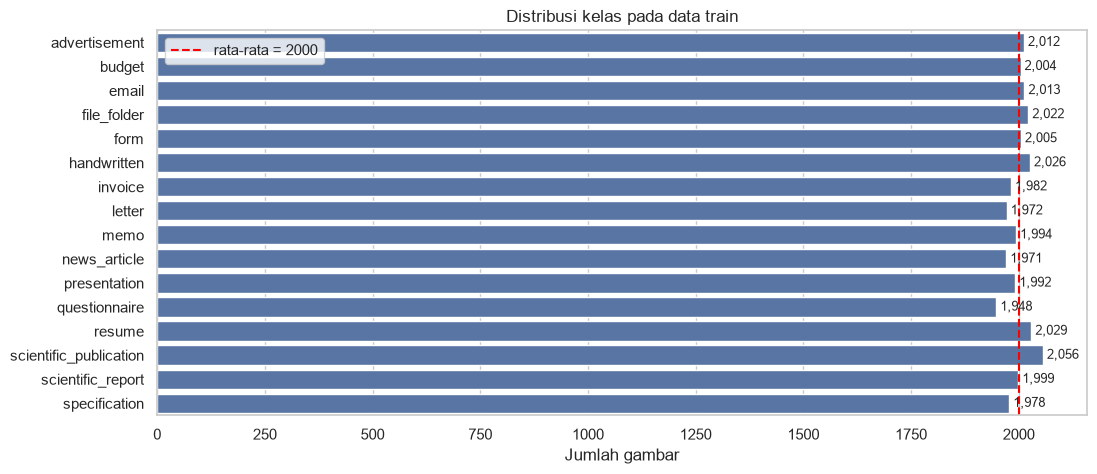

In [13]:
label_counts = train_df["class_name"].value_counts().reindex(CLASS_NAMES)
label_tab = pd.DataFrame({"label_id": range(16), "jumlah": label_counts.values,
                          "persen": label_counts.values / label_counts.sum() * 100}, index=CLASS_NAMES)
display(label_tab)
imbalance = label_counts.max() / label_counts.min()
print(f"Rasio kelas terbanyak/tersedikit: {imbalance:.3f}")
print(f"Koefisien variasi jumlah per kelas: {label_counts.std() / label_counts.mean():.4f}")

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=label_counts.values, y=label_counts.index, color="#4C72B0", ax=ax)
ax.axvline(label_counts.mean(), color="red", ls="--", label=f"rata-rata = {label_counts.mean():.0f}")
for i, v in enumerate(label_counts.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set(xlabel="Jumlah gambar", ylabel="", title="Distribusi kelas pada data train")
ax.legend()
save_fig("class_distribution")
plt.show()

### 4.2 Metadata gambar


--- mode ---


,train_%,test_%
mode,,
L,100.0000,100.0000



--- dpi ---


,train_%,test_%
dpi,,
72x72,100.0000,100.0000



--- compression ---


,train_%,test_%
compression,,
packbits,100.0000,100.0000



--- n_frames ---


,train_%,test_%
n_frames,,
1,100.0000,100.0000



--- orientation ---


,train_%,test_%
orientation,,
portrait,99.9125,99.9124
landscape,0.0562,0.0500
square,0.0312,0.0375


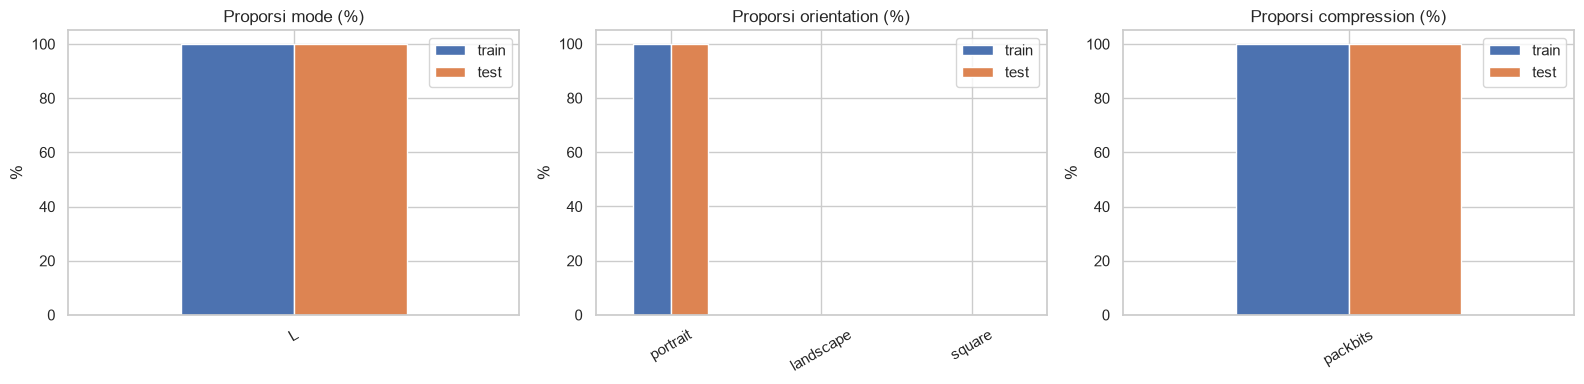

In [14]:
cat_cols = ["mode", "dpi", "compression", "n_frames", "orientation"]
for c in cat_cols:
    tab = pd.concat([
        train_df[c].astype(str).value_counts(normalize=True).mul(100).rename("train_%"),
        test_df[c].astype(str).value_counts(normalize=True).mul(100).rename("test_%"),
    ], axis=1).fillna(0)
    print(f"\n--- {c} ---")
    display(tab.head(10))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["mode", "orientation", "compression"]):
    tab = pd.concat([
        train_df[c].astype(str).value_counts(normalize=True).mul(100).rename("train"),
        test_df[c].astype(str).value_counts(normalize=True).mul(100).rename("test"),
    ], axis=1).fillna(0).head(8)
    tab.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
    ax.set(title=f"Proporsi {c} (%)", xlabel="", ylabel="%")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
save_fig("categorical_metadata")
plt.show()

## 5. Variabel Numerik
### 5.1 Ekstraksi fitur
Fitur header tersedia untuk seluruh gambar. Fitur piksel dihitung pada sampel stratified per kelas.

- `mean_intensity`: rata-rata kecerahan (0 hitam, 1 putih)
- `std_intensity`: kontras
- `ink_ratio`: proporsi piksel gelap
- `edge_density`: rata-rata perubahan intensitas antar piksel bertetangga
- `blank_row_ratio`, `blank_col_ratio`: proporsi baris/kolom tanpa piksel gelap

In [15]:
readable_train = train_df[train_df["readable"]]
if N_SAMPLE_PER_CLASS is None:
    sample_idx = readable_train.index
else:
    sample_idx = (readable_train.groupby("label", group_keys=False)
                  .apply(lambda g: g.sample(min(len(g), N_SAMPLE_PER_CLASS), random_state=SEED)).index)
test_sample_idx = test_df[test_df["readable"]].sample(
    min(N_SAMPLE_TEST, int(test_df["readable"].sum())), random_state=SEED).index

res_tr = parallel_map(pixel_features, list(train_df.loc[sample_idx, "path"]), "Fitur piksel train")
res_te = parallel_map(pixel_features, list(test_df.loc[test_sample_idx, "path"]), "Fitur piksel test")

train_s = pd.concat([train_df.loc[sample_idx].reset_index(drop=True),
                     pd.DataFrame([r[0] for r in res_tr])], axis=1)
test_s = pd.concat([test_df.loc[test_sample_idx].reset_index(drop=True),
                    pd.DataFrame([r[0] for r in res_te])], axis=1)
thumbs_tr = np.stack([r[1] if r[1] is not None else np.ones((THUMB_SIZE, THUMB_SIZE), np.float32) for r in res_tr])
thumbs_te = np.stack([r[1] if r[1] is not None else np.ones((THUMB_SIZE, THUMB_SIZE), np.float32) for r in res_te])
keep = train_s["pixel_ok"].values
train_s, thumbs_tr = train_s[keep].reset_index(drop=True), thumbs_tr[keep]
test_s = test_s[test_s["pixel_ok"]].reset_index(drop=True)
print(f"Sampel train: {len(train_s):,} gambar | sampel test: {len(test_s):,} gambar")

Fitur piksel test: 100%|██████████| 1000/1000 [00:19<00:00, 51.88it/s]


Sampel train: 3,200 gambar | sampel test: 1,000 gambar


### 5.2 Statistik deskriptif

In [16]:
HEADER_FEATS = ["width", "height", "aspect_ratio", "megapixel", "file_kb"]
PIXEL_FEATS = ["mean_intensity", "std_intensity", "ink_ratio", "edge_density", "blank_row_ratio", "blank_col_ratio"]
NUM_FEATS = HEADER_FEATS + PIXEL_FEATS

desc_header = train_df[HEADER_FEATS].describe().T
desc_header["skewness"] = train_df[HEADER_FEATS].skew()
desc_header["kurtosis"] = train_df[HEADER_FEATS].kurt()
print("Fitur header (seluruh train):")
display(desc_header)

desc_pixel = train_s[PIXEL_FEATS].describe().T
desc_pixel["skewness"] = train_s[PIXEL_FEATS].skew()
desc_pixel["kurtosis"] = train_s[PIXEL_FEATS].kurt()
print("Fitur piksel (sampel train):")
display(desc_pixel)

print("Ukuran gambar (lebar x tinggi) yang paling sering muncul:")
display((train_df["width"].astype("Int64").astype(str) + " x " + train_df["height"].astype("Int64").astype(str))
        .value_counts().head(10).to_frame("jumlah").T)
pd.concat([desc_header, desc_pixel]).to_csv(METRIC_DIR / "eda_numeric_summary.csv")

Fitur header (seluruh train):


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
width,32002.0000,766.3389,27.7844,606.0000,754.0000,762.0000,777.0000,2542.0000,14.1150,671.9598
height,32002.0000,1000.0000,0.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,0.0000,0.0000
aspect_ratio,32002.0000,1.3063,0.0407,0.3934,1.2870,1.3123,1.3263,1.6502,-0.3283,47.2163
megapixel,32002.0000,0.7663,0.0278,0.6060,0.7540,0.7620,0.7770,2.5420,14.1150,671.9598
file_kb,32003.0000,118.8484,83.2119,13.3164,64.0693,99.9238,150.8652,796.4199,2.0525,6.7917


Fitur piksel (sampel train):


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
mean_intensity,3200.0000,0.9199,0.1068,0.0500,0.9142,0.9500,0.9723,0.9995,-3.8208,17.5576
std_intensity,3200.0000,0.1997,0.0909,0.0192,0.1392,0.1860,0.2402,0.4965,0.9531,0.9826
ink_ratio,3200.0000,0.0787,0.1073,0.0005,0.0270,0.0486,0.0839,0.9504,3.8665,17.8169
edge_density,3200.0000,0.0340,0.0247,0.0004,0.0167,0.0292,0.0452,0.1870,1.5654,4.0871
blank_row_ratio,3200.0000,0.2882,0.2527,0.0000,0.0710,0.2220,0.4610,0.9740,0.7143,-0.5303
blank_col_ratio,3200.0000,0.1721,0.1744,0.0000,0.0545,0.1254,0.2308,0.9640,2.0188,4.8159


Ukuran gambar (lebar x tinggi) yang paling sering muncul:


,754 x 1000,777 x 1000,762 x 1000,772 x 1000,771 x 1000,802 x 1000,778 x 1000,781 x 1000,779 x 1000,780 x 1000
jumlah,15060,3843,2745,774,671,540,437,356,323,304


## 6. Analisis Univariat
### 6.1 Distribusi

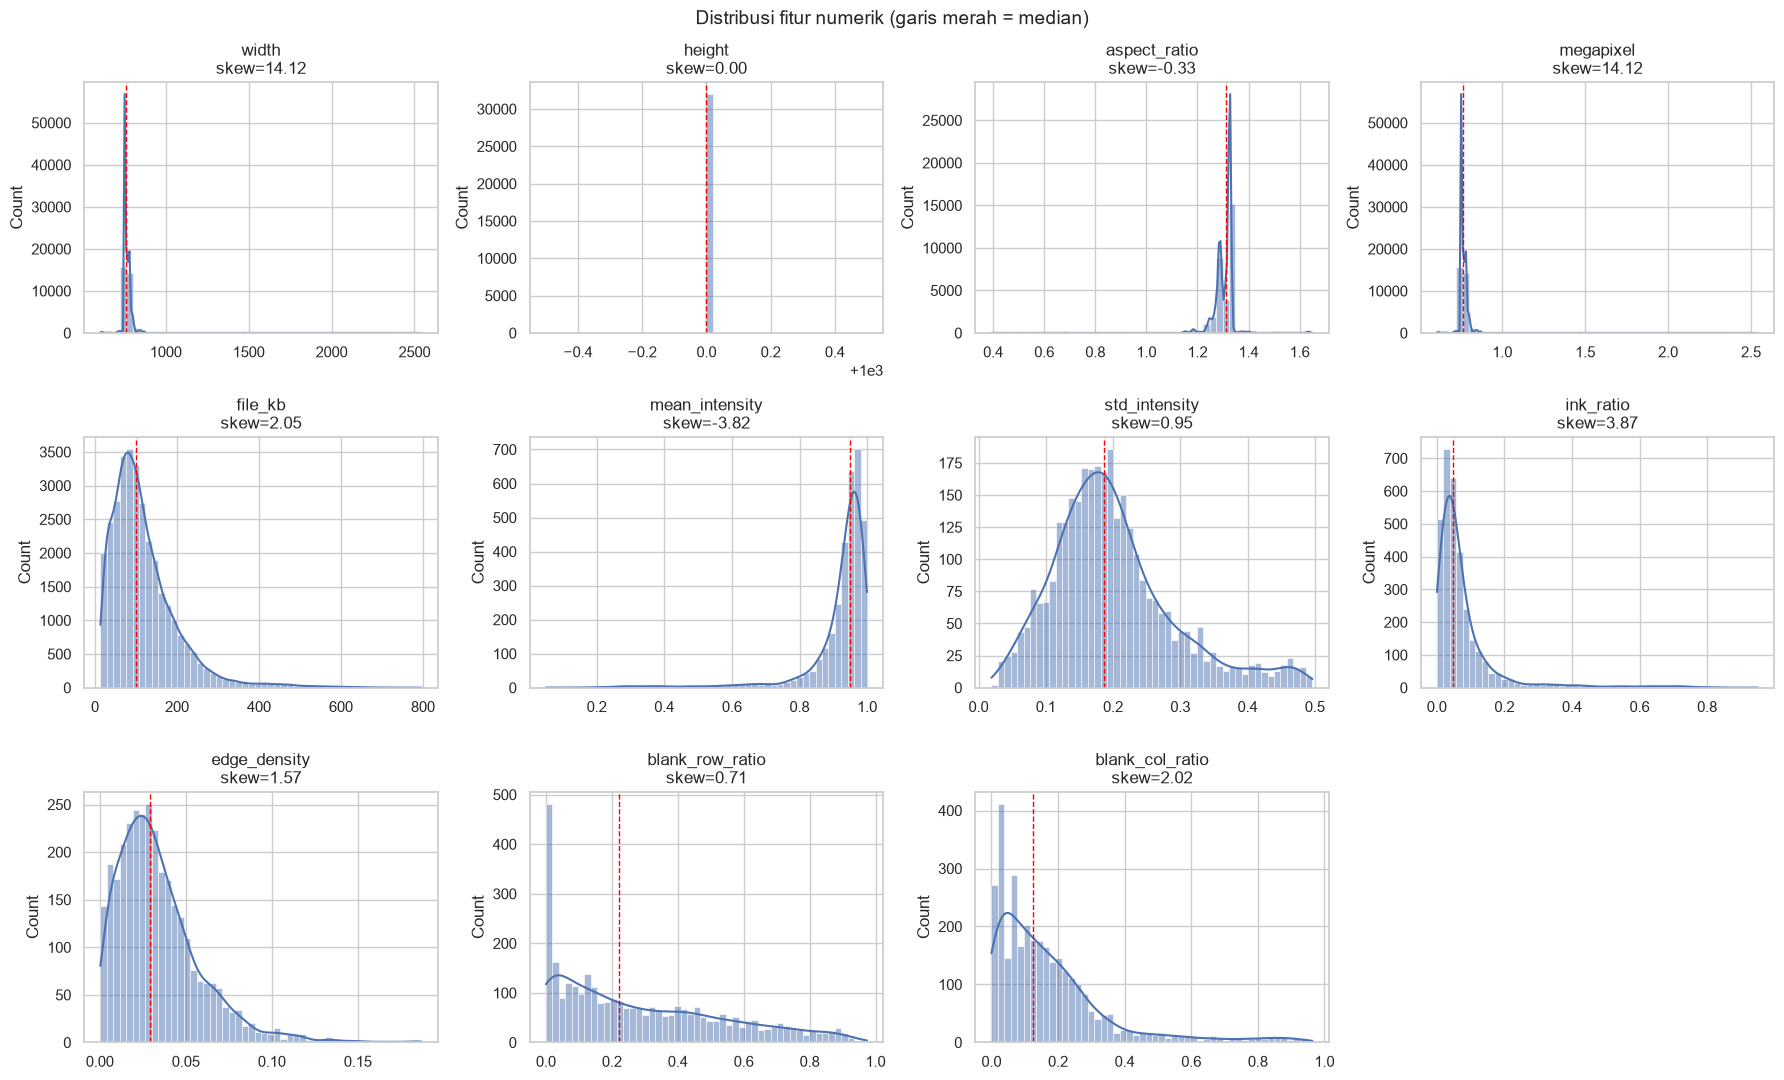

In [17]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.ravel()
for ax, c in zip(axes, NUM_FEATS):
    src = train_df if c in HEADER_FEATS else train_s
    sns.histplot(src[c].dropna(), bins=50, kde=True, ax=ax, color="#4C72B0")
    ax.axvline(src[c].median(), color="red", ls="--", lw=1)
    ax.set_title(f"{c}\nskew={src[c].skew():.2f}")
    ax.set_xlabel("")
for ax in axes[len(NUM_FEATS):]:
    ax.axis("off")
plt.suptitle("Distribusi fitur numerik (garis merah = median)", fontsize=14)
plt.tight_layout()
save_fig("univariate_hist")
plt.show()

### 6.2 Outlier (IQR)

,batas_bawah,batas_atas,n_outlier,pct_outlier
width,719.5000,811.5000,1034.0000,3.2310
height,1000.0000,1000.0000,0.0000,0.0000
aspect_ratio,1.2281,1.3851,995.0000,3.1092
megapixel,0.7195,0.8115,1034.0000,3.2310
file_kb,-66.1245,281.0591,1361.0000,4.2527
mean_intensity,0.8270,1.0594,278.0000,8.6875
std_intensity,-0.0123,0.3917,163.0000,5.0938
ink_ratio,-0.0583,0.1693,280.0000,8.7500
edge_density,-0.0259,0.0879,105.0000,3.2812
blank_row_ratio,-0.5140,1.0460,0.0000,0.0000


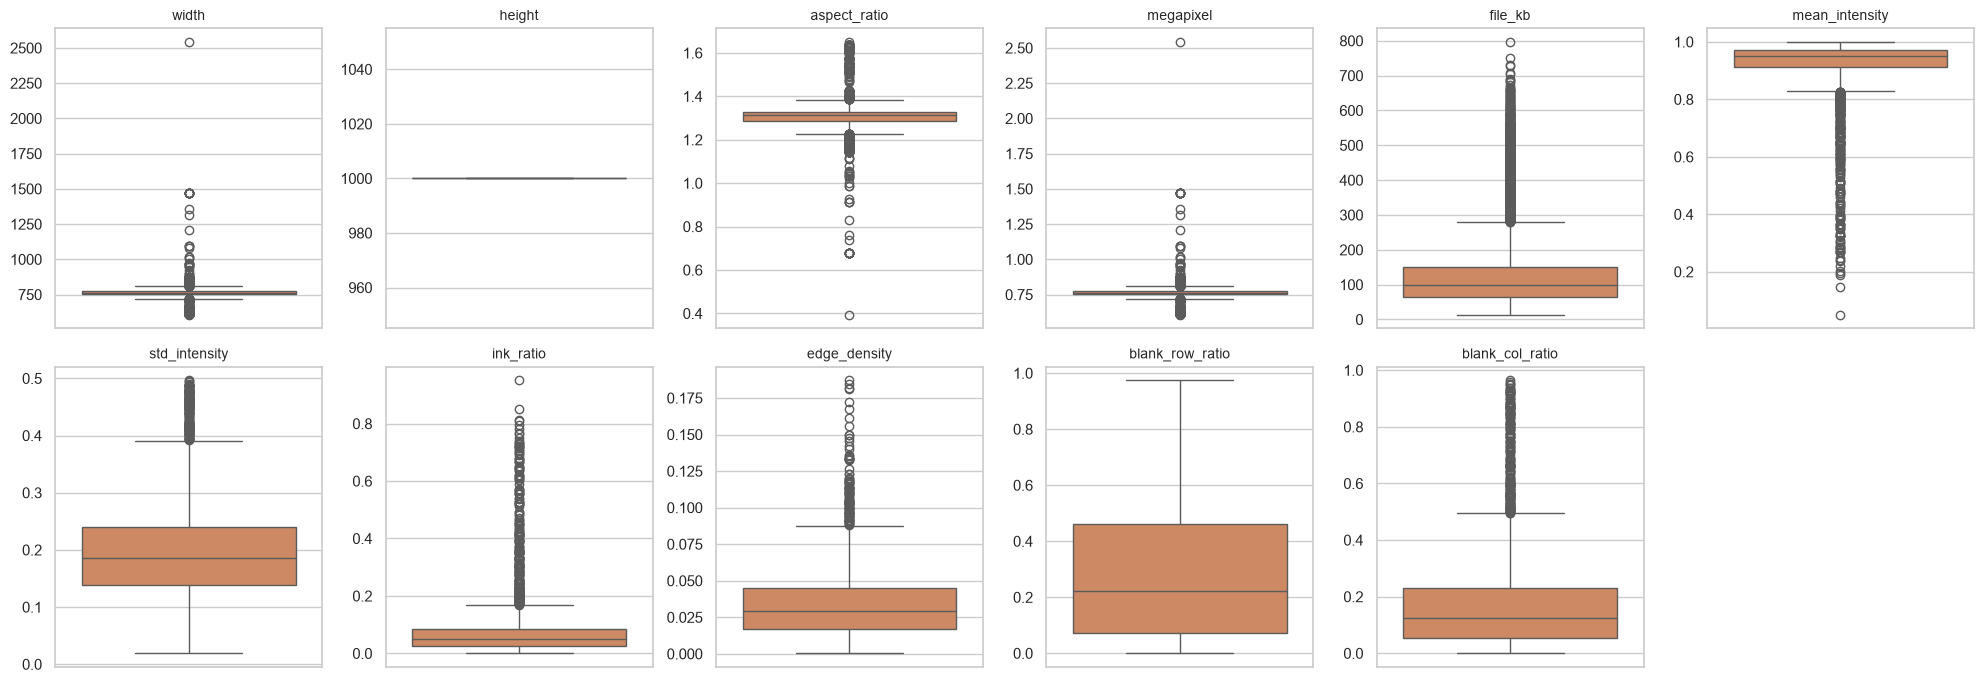

In [18]:
def iqr_outliers(s):
    """Menghitung jumlah dan persentase outlier dengan aturan 1.5 x IQR."""
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n = int(((s < lo) | (s > hi)).sum())
    return {"batas_bawah": lo, "batas_atas": hi, "n_outlier": n, "pct_outlier": n / len(s) * 100}

out_tab = pd.DataFrame({c: iqr_outliers((train_df if c in HEADER_FEATS else train_s)[c]) for c in NUM_FEATS}).T
display(out_tab)

fig, axes = plt.subplots(2, 6, figsize=(20, 7))
axes = axes.ravel()
for ax, c in zip(axes, NUM_FEATS):
    src = train_df if c in HEADER_FEATS else train_s
    sns.boxplot(y=src[c], ax=ax, color="#DD8452")
    ax.set_title(c, fontsize=10)
    ax.set_ylabel("")
for ax in axes[len(NUM_FEATS):]:
    ax.axis("off")
plt.tight_layout()
save_fig("univariate_boxplot")
plt.show()

## 7. Analisis Bivariat
### 7.1 Fitur per kelas

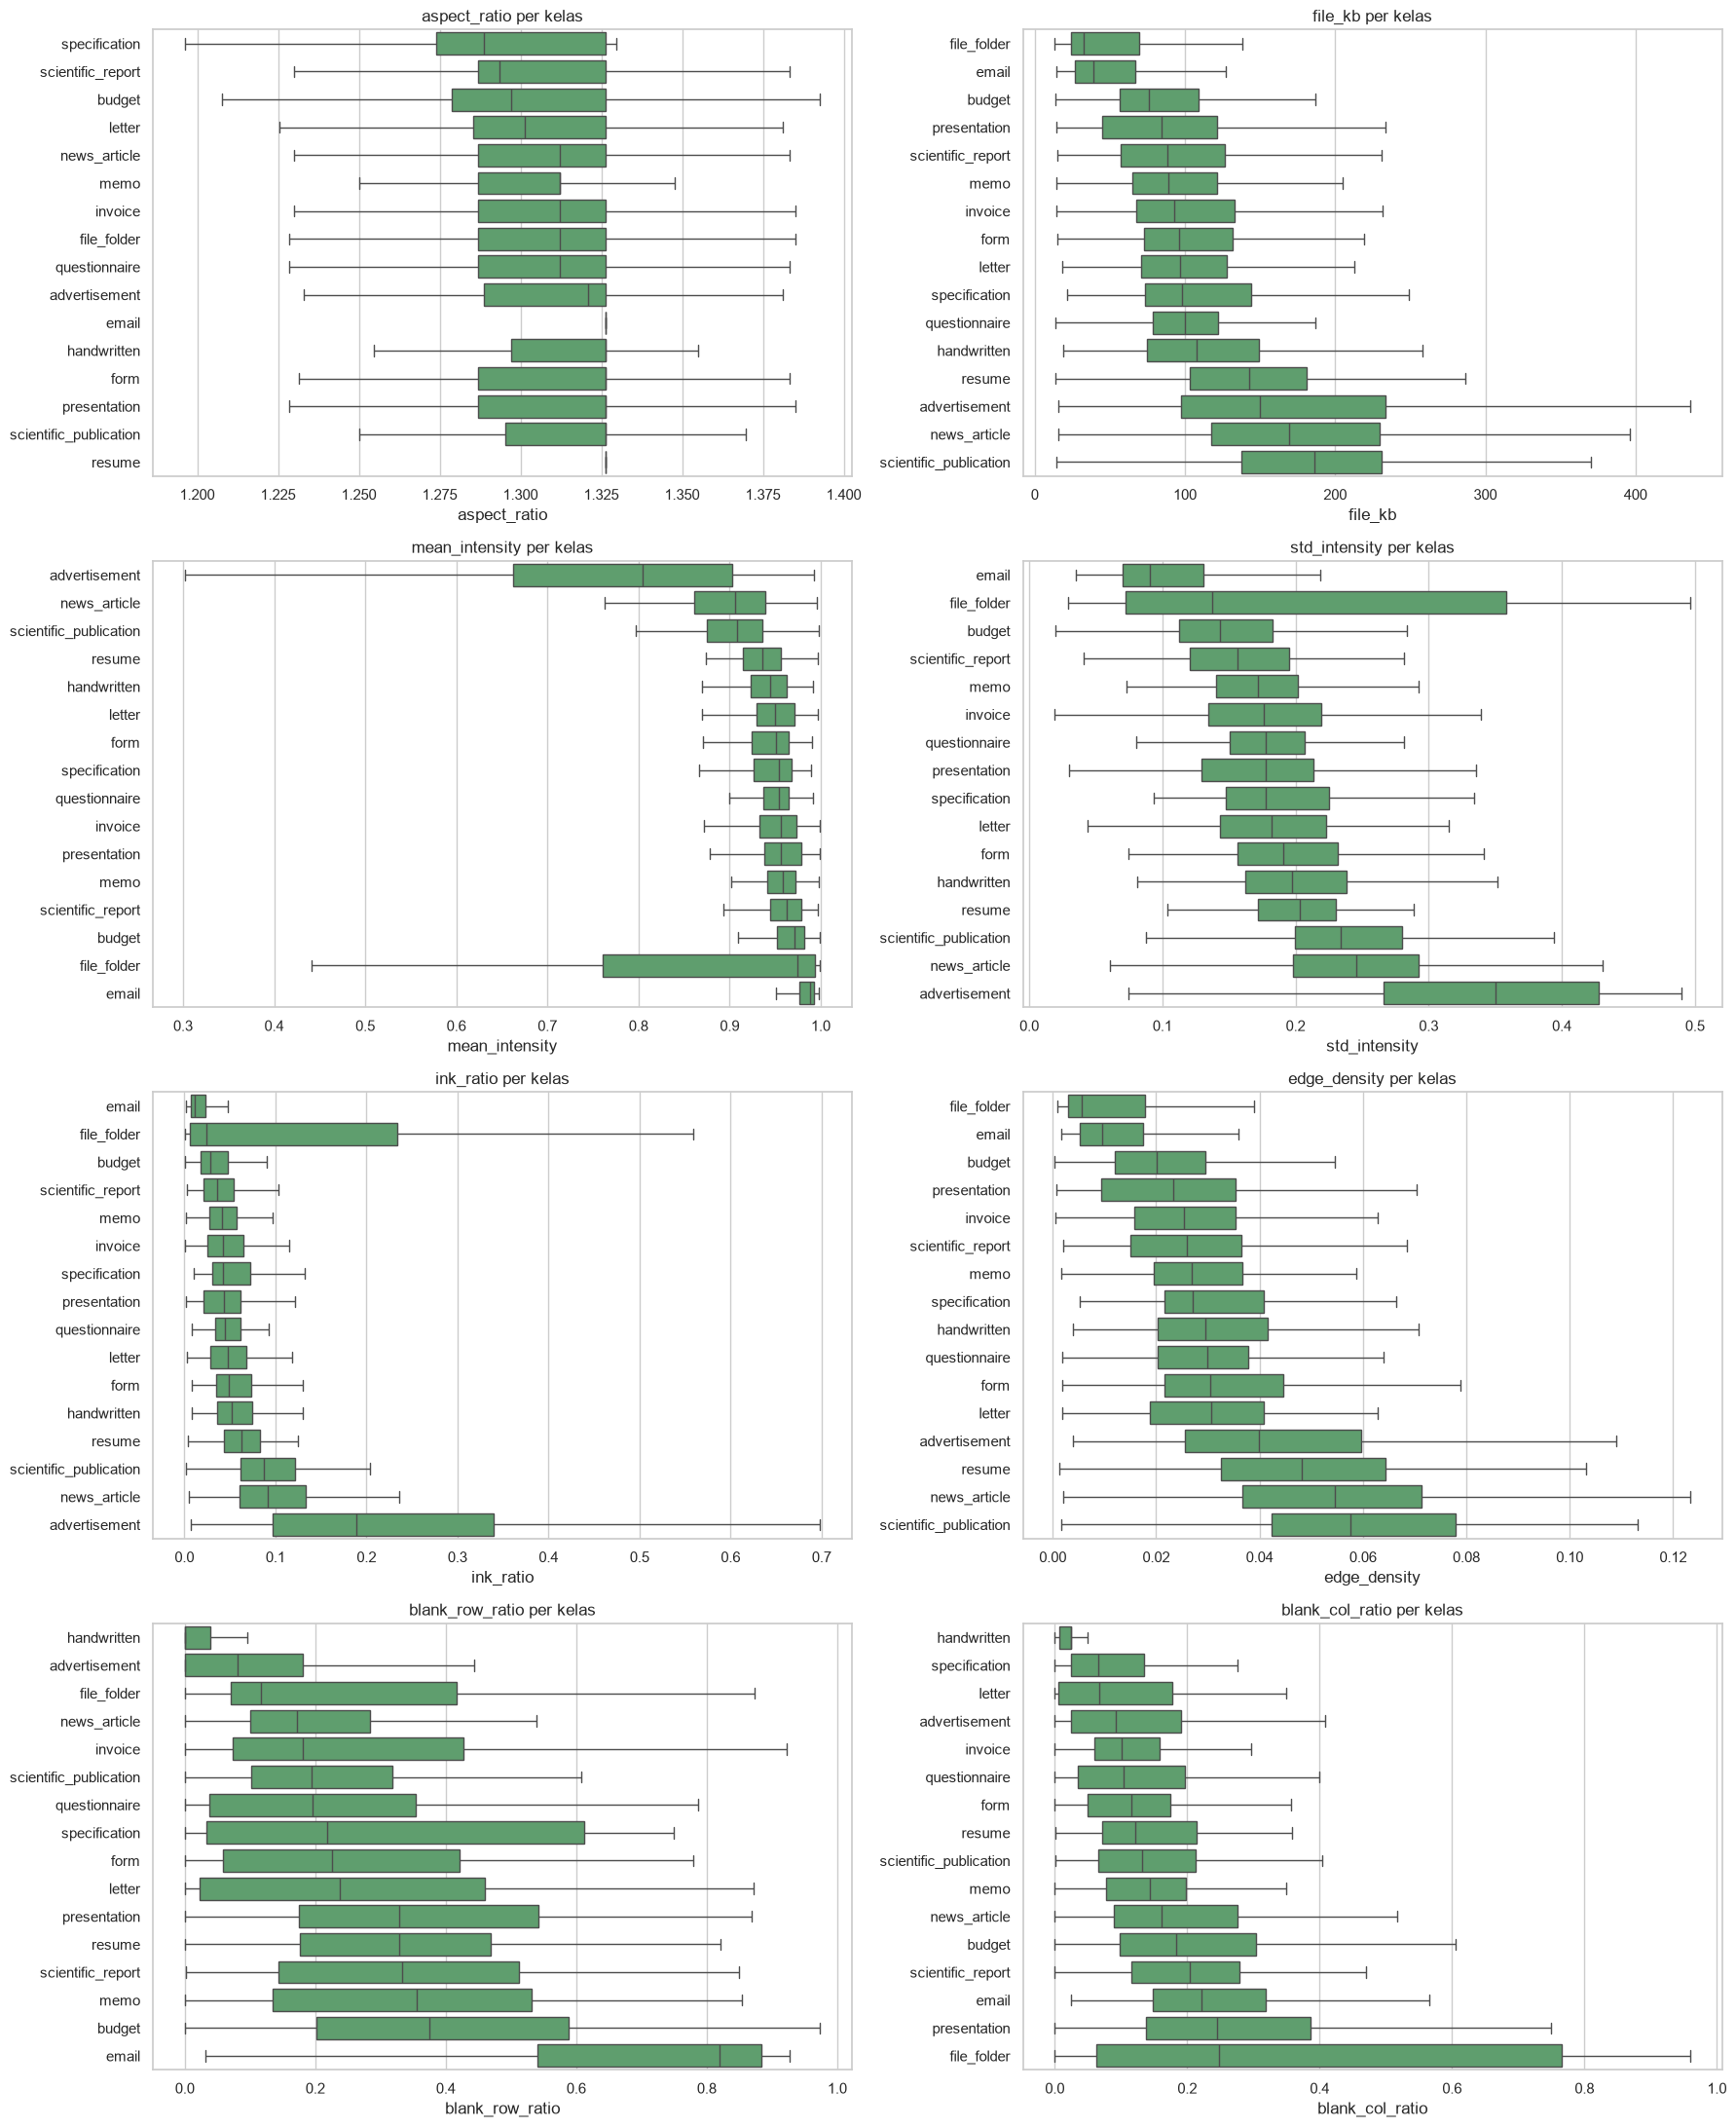

In [19]:
plot_feats = ["aspect_ratio", "file_kb"] + PIXEL_FEATS
fig, axes = plt.subplots(4, 2, figsize=(18, 22))
for ax, c in zip(axes.ravel(), plot_feats):
    src = train_df if c in HEADER_FEATS else train_s
    order = src.groupby("class_name")[c].median().sort_values().index
    sns.boxplot(data=src, y="class_name", x=c, order=order, ax=ax, showfliers=False, color="#55A868")
    ax.set_title(f"{c} per kelas")
    ax.set_ylabel("")
plt.tight_layout()
save_fig("bivariate_box_by_class")
plt.show()

### 7.2 Uji Kruskal-Wallis
Digunakan uji non-parametrik karena distribusi fitur tidak normal. Besar efek diukur dengan epsilon-squared (0,01 kecil; 0,08 sedang; 0,26 besar).

,fitur,H,p_value,epsilon_sq,besar_efek
0,edge_density,980.6230,0.0000,0.3065,besar
1,mean_intensity,889.8544,0.0000,0.2782,besar
2,file_kb,8806.7017,0.0000,0.2752,besar
3,ink_ratio,877.5845,0.0000,0.2743,besar
4,std_intensity,853.5170,0.0000,0.2668,besar
5,blank_col_ratio,766.6665,0.0000,0.2397,sedang
6,blank_row_ratio,757.3090,0.0000,0.2367,sedang
7,aspect_ratio,3590.8402,0.0000,0.1122,sedang
8,width,3590.8402,0.0000,0.1122,sedang
9,megapixel,3590.8402,0.0000,0.1122,sedang


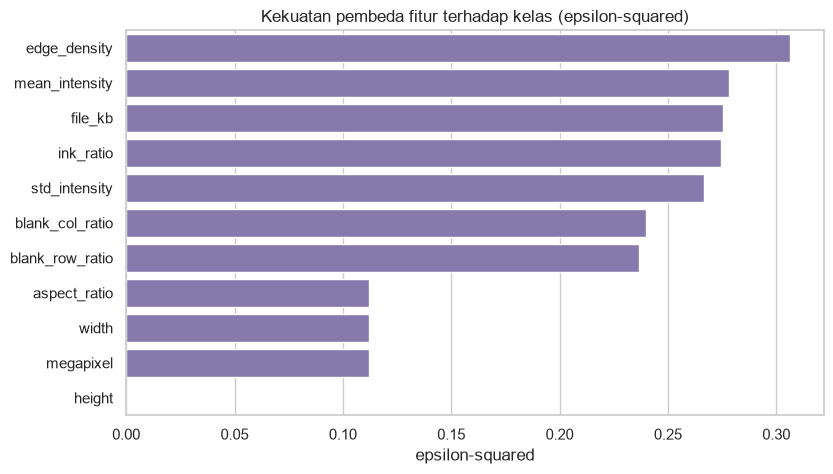

In [20]:
rows = []
for c in NUM_FEATS:
    src = (train_df if c in HEADER_FEATS else train_s).dropna(subset=[c])
    groups = [g[c].values for _, g in src.groupby("label")]
    if src[c].nunique() < 2:
        rows.append({"fitur": c, "H": np.nan, "p_value": np.nan, "epsilon_sq": 0.0})
        continue
    h, p = stats.kruskal(*groups)
    rows.append({"fitur": c, "H": h, "p_value": p, "epsilon_sq": h / (len(src) - 1)})
kw = pd.DataFrame(rows).sort_values("epsilon_sq", ascending=False).reset_index(drop=True)
kw["besar_efek"] = pd.cut(kw["epsilon_sq"], [-1, 0.01, 0.08, 0.26, 2], labels=["sangat kecil", "kecil", "sedang", "besar"])
display(kw)
kw.to_csv(METRIC_DIR / "eda_kruskal_wallis.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=kw, x="epsilon_sq", y="fitur", color="#8172B3", ax=ax)
ax.set(title="Kekuatan pembeda fitur terhadap kelas (epsilon-squared)", xlabel="epsilon-squared", ylabel="")
save_fig("bivariate_kruskal")
plt.show()

### 7.3 Orientasi halaman per kelas

orientation,landscape,portrait,square
class_name,,,
advertisement,0.4500,99.1600,0.4000
budget,0.0000,100.0000,0.0000
email,0.0000,100.0000,0.0000
file_folder,0.0000,100.0000,0.0000
form,0.2000,99.8000,0.0000
handwritten,0.0500,99.9500,0.0000
invoice,0.0000,100.0000,0.0000
letter,0.0500,99.9000,0.0500
memo,0.0500,99.9500,0.0000


Uji chi-square independensi: chi2 = 169.10, df = 30, p-value = 2.490e-21


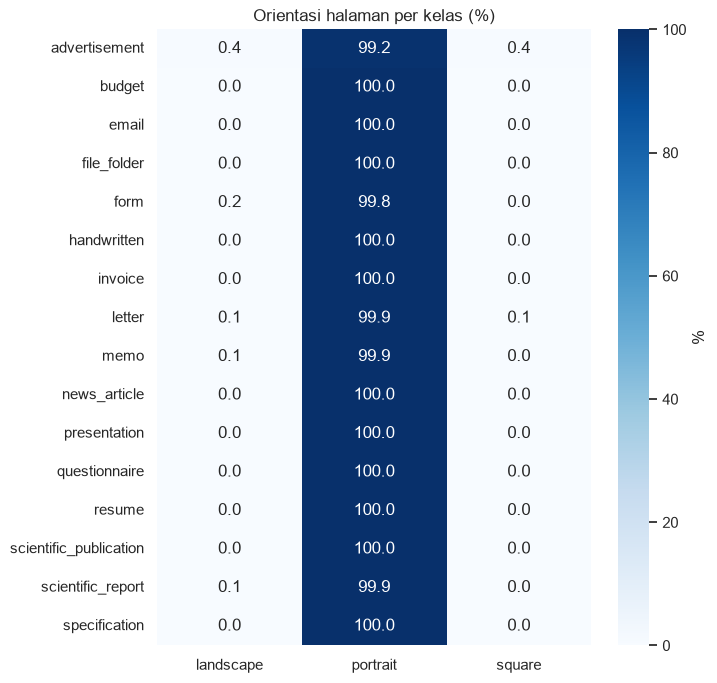

In [21]:
ct = pd.crosstab(train_df["class_name"], train_df["orientation"], normalize="index").mul(100).reindex(CLASS_NAMES)
display(ct.round(2))
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(train_df["class_name"], train_df["orientation"]))
print(f"Uji chi-square independensi: chi2 = {chi2:.2f}, df = {dof}, p-value = {p:.3e}")

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "%"})
ax.set(title="Orientasi halaman per kelas (%)", ylabel="", xlabel="")
save_fig("bivariate_orientation")
plt.show()

### 7.4 Lebar dan tinggi

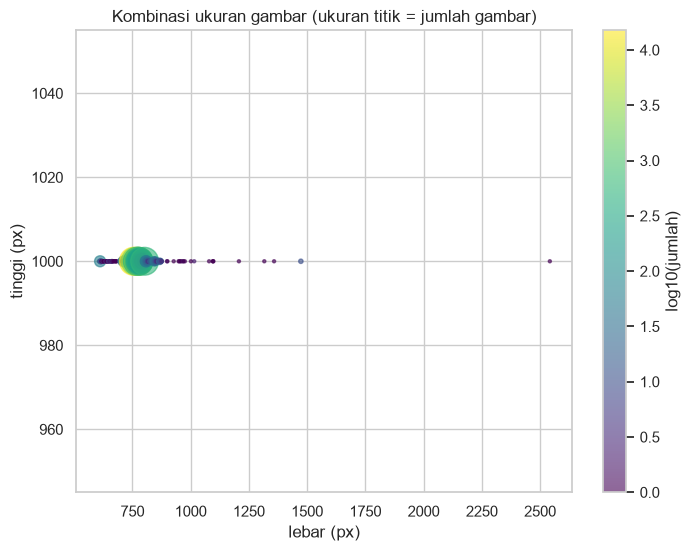

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
sizes = train_df.groupby(["width", "height"]).size().reset_index(name="n")
sc = ax.scatter(sizes["width"], sizes["height"], s=np.clip(sizes["n"], 5, 400), alpha=0.6, c=np.log10(sizes["n"]), cmap="viridis")
ax.set(xlabel="lebar (px)", ylabel="tinggi (px)", title="Kombinasi ukuran gambar (ukuran titik = jumlah gambar)")
plt.colorbar(sc, label="log10(jumlah)")
save_fig("bivariate_width_height")
plt.show()

## 8. Analisis Multivariat
### 8.1 Korelasi Spearman

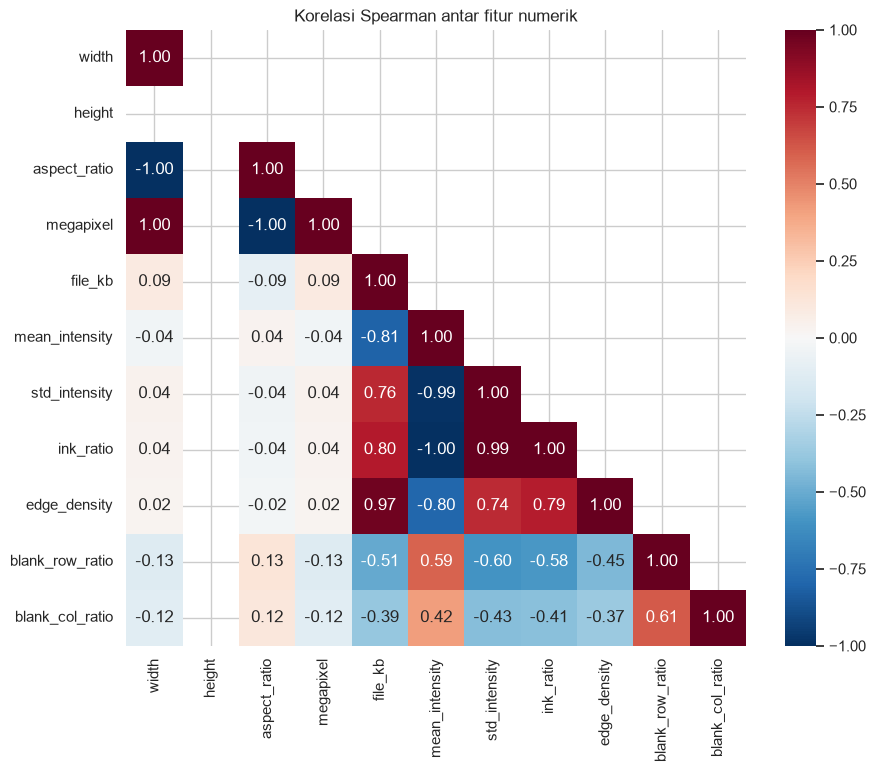

Pasangan fitur dengan korelasi terkuat:


rho
aspect_ratio   width          -1.0000
megapixel      width           1.0000
               aspect_ratio   -1.0000
ink_ratio      mean_intensity -0.9978
               std_intensity   0.9934
std_intensity  mean_intensity -0.9901
edge_density   file_kb         0.9697
mean_intensity file_kb        -0.8105

In [23]:
corr = train_s[NUM_FEATS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelasi Spearman antar fitur numerik")
save_fig("multivariate_correlation")
plt.show()

pairs = corr.where(mask.T & ~np.eye(len(corr), dtype=bool)).stack().sort_values(key=abs, ascending=False)
print("Pasangan fitur dengan korelasi terkuat:")
display(pairs.head(8).to_frame("rho"))

### 8.2 Profil kelas
Median fitur per kelas yang distandarkan antar kelas.

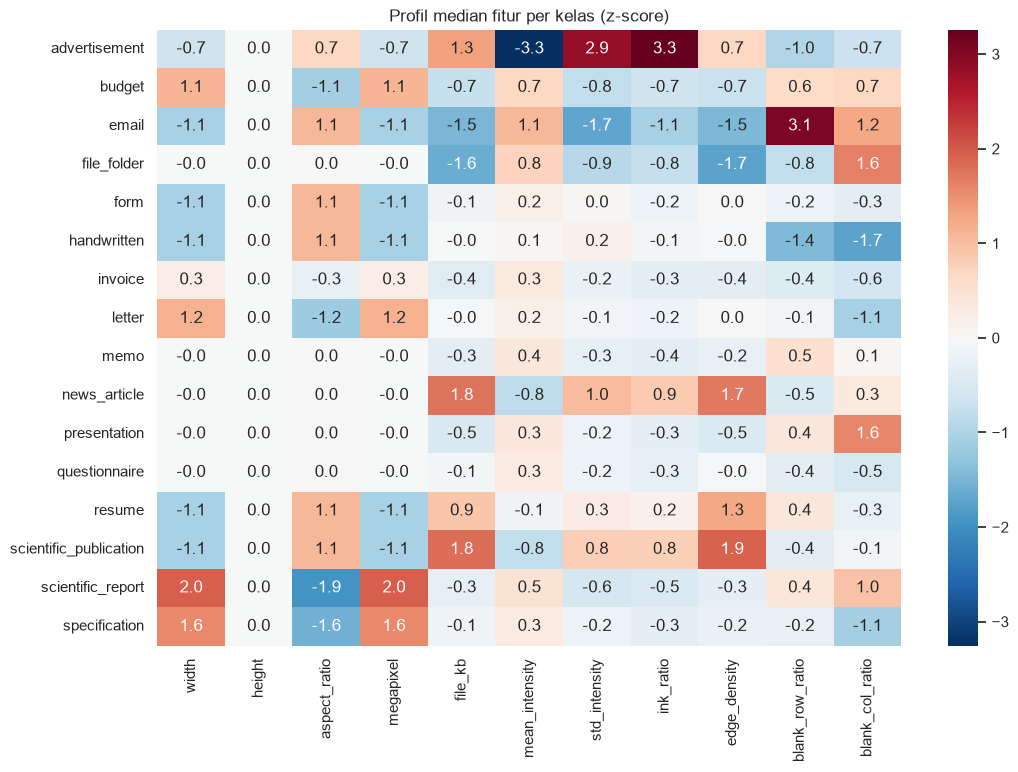

In [24]:
profile = train_s.groupby("class_name")[NUM_FEATS].median().reindex(CLASS_NAMES)
profile_z = (profile - profile.mean()) / profile.std().replace(0, 1)
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(profile_z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title="Profil median fitur per kelas (z-score)", ylabel="")
save_fig("multivariate_class_profile")
plt.show()

### 8.3 Pairplot

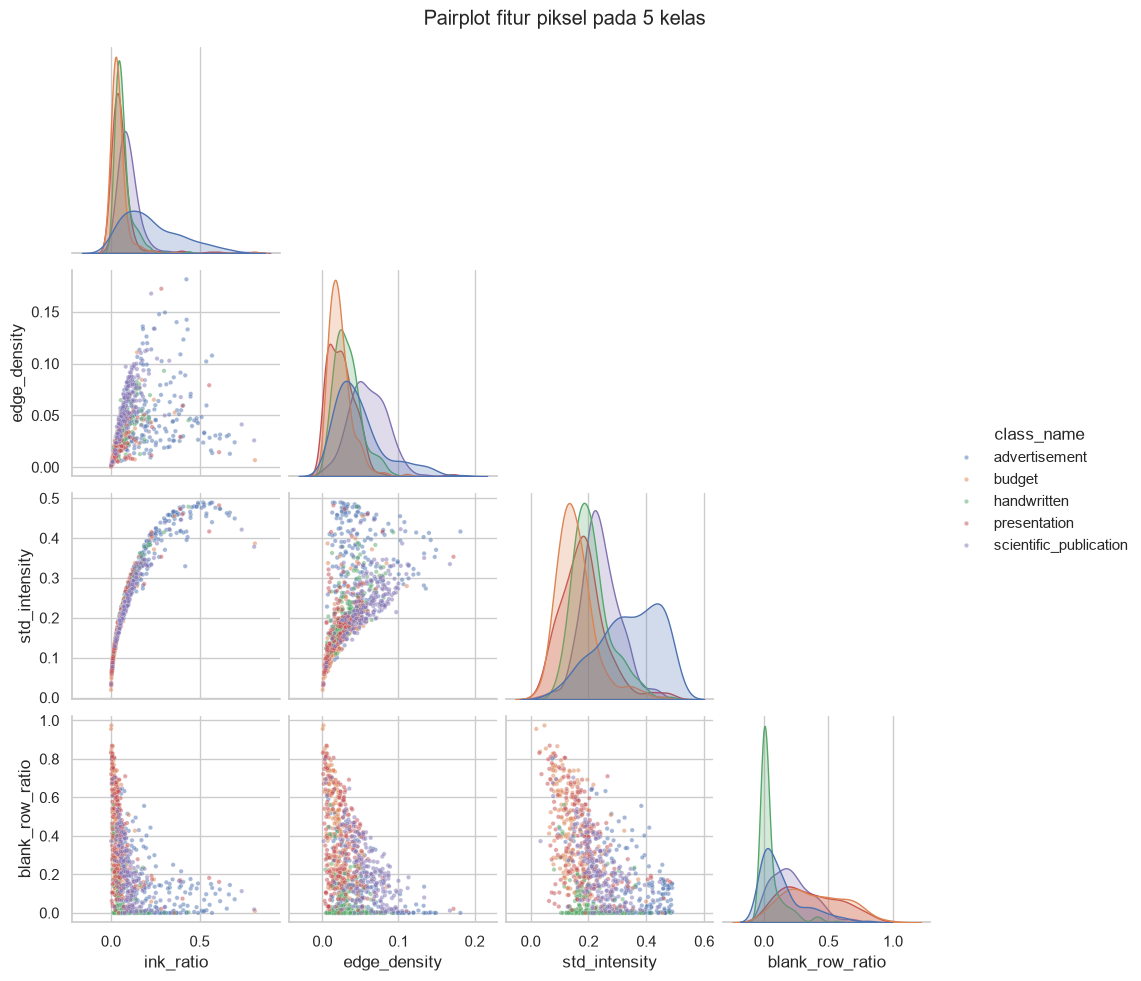

In [25]:
pp_classes = ["handwritten", "budget", "presentation", "scientific_publication", "advertisement"]
pp = train_s[train_s["class_name"].isin(pp_classes)]
g = sns.pairplot(pp, vars=["ink_ratio", "edge_density", "std_intensity", "blank_row_ratio"],
                 hue="class_name", corner=True, plot_kws={"s": 10, "alpha": 0.5}, height=2.4)
g.fig.suptitle("Pairplot fitur piksel pada 5 kelas", y=1.02)
plt.savefig(FIG_DIR / "eda_multivariate_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.4 Citra rata-rata per kelas
Thumbnail setiap kelas dirata-ratakan untuk melihat pola tata letak yang umum.

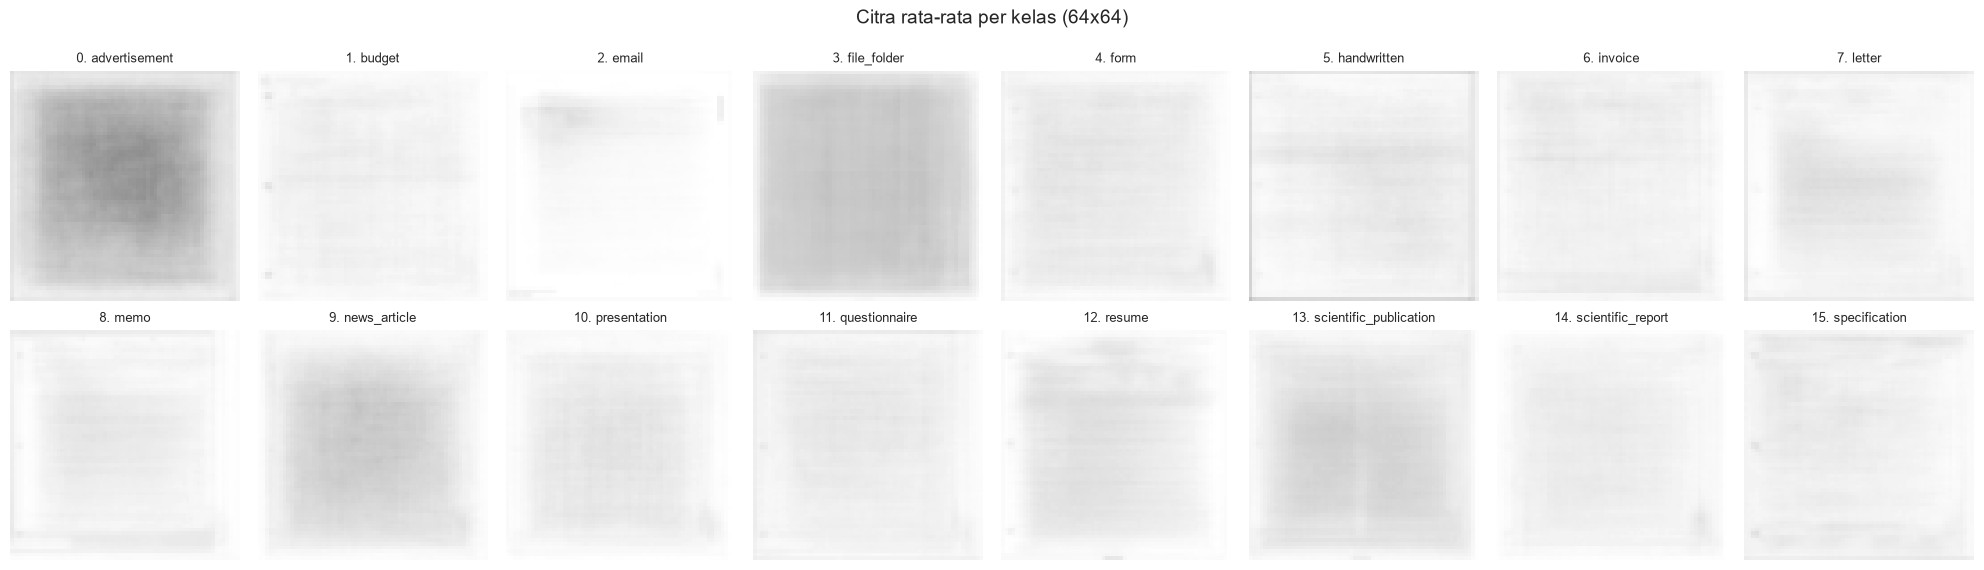

In [26]:
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
for ax, (i, c) in zip(axes.ravel(), enumerate(CLASS_NAMES)):
    m = train_s["label"].values == i
    if m.any():
        ax.imshow(thumbs_tr[m].mean(axis=0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{i}. {c}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Citra rata-rata per kelas ({THUMB_SIZE}x{THUMB_SIZE})", fontsize=14)
plt.tight_layout()
save_fig("multivariate_mean_image")
plt.show()

### 8.5 PCA dan t-SNE
Thumbnail 64x64 diproyeksikan ke dua dimensi untuk melihat keterpisahan kelas berdasarkan piksel mentah.

Varians dijelaskan 2 komponen pertama: 46.05%
Varians dijelaskan 50 komponen   : 83.63%


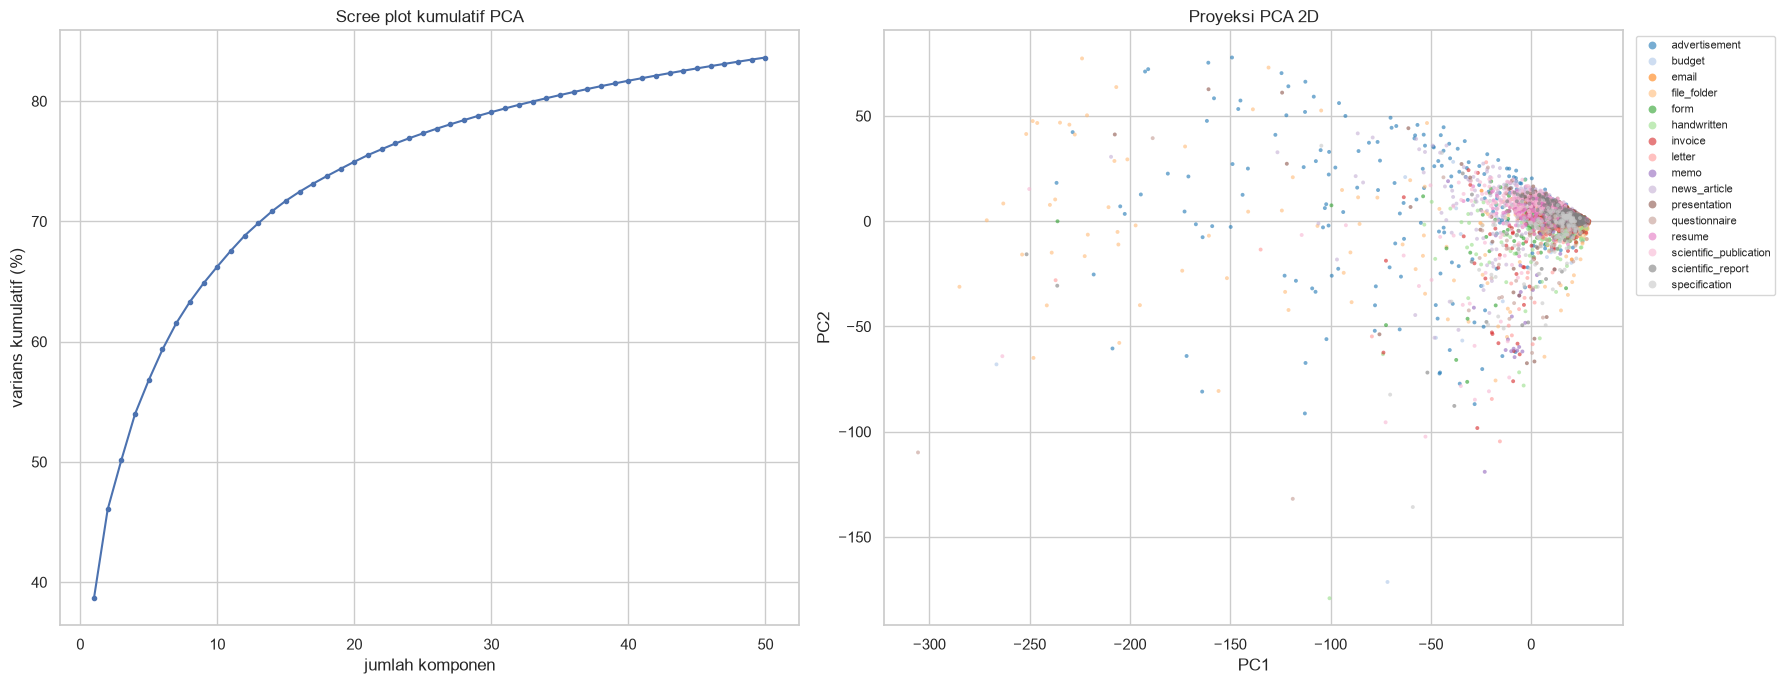

In [27]:
X = thumbs_tr.reshape(len(thumbs_tr), -1)
X_std = StandardScaler().fit_transform(X)
n_comp = min(50, X_std.shape[0] - 1, X_std.shape[1])
pca = PCA(n_components=n_comp, random_state=SEED).fit(X_std)
Z = pca.transform(X_std)
cum = np.cumsum(pca.explained_variance_ratio_)
print(f"Varians dijelaskan 2 komponen pertama: {cum[1] * 100:.2f}%")
print(f"Varians dijelaskan {n_comp} komponen   : {cum[-1] * 100:.2f}%")

palette = sns.color_palette("tab20", 16)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].plot(range(1, n_comp + 1), cum * 100, marker="o", ms=3)
axes[0].set(xlabel="jumlah komponen", ylabel="varians kumulatif (%)", title="Scree plot kumulatif PCA")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=train_s["class_name"], hue_order=CLASS_NAMES,
                palette=palette, s=8, alpha=0.6, ax=axes[1], linewidth=0)
axes[1].set(xlabel="PC1", ylabel="PC2", title="Proyeksi PCA 2D")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, markerscale=2)
plt.tight_layout()
save_fig("multivariate_pca")
plt.show()

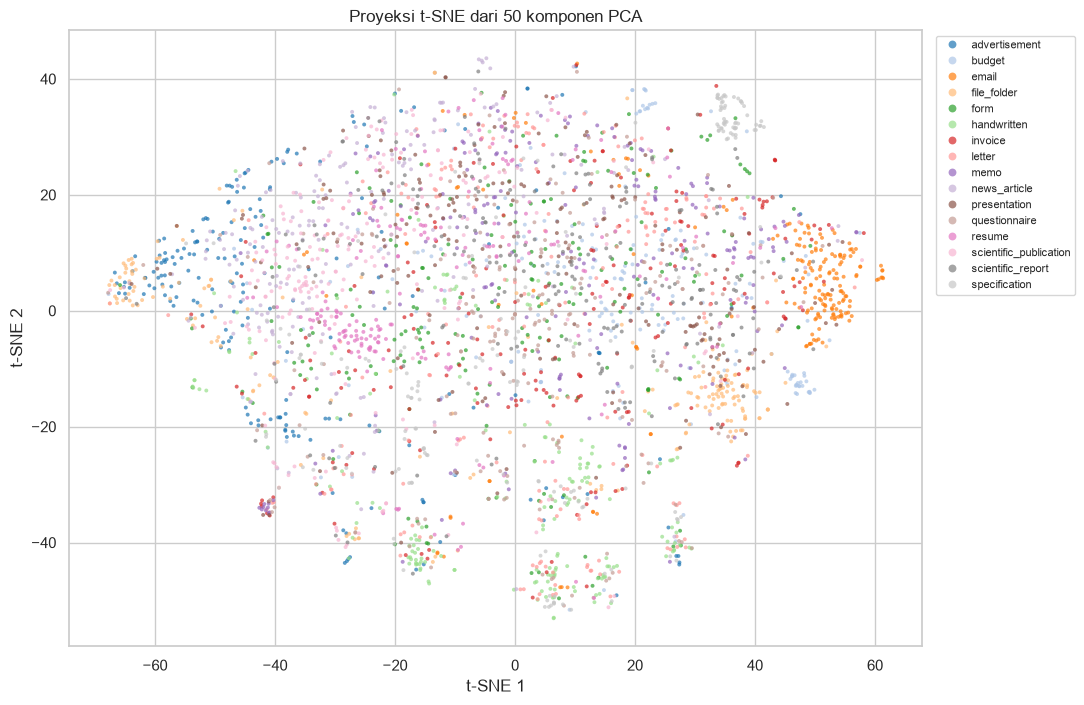

In [28]:
if RUN_TSNE:
    perp = min(30, max(5, (len(Z) - 1) // 3))
    T = TSNE(n_components=2, perplexity=perp, init="pca", random_state=SEED).fit_transform(Z)
    fig, ax = plt.subplots(figsize=(11, 8))
    sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=train_s["class_name"], hue_order=CLASS_NAMES,
                    palette=palette, s=8, alpha=0.7, ax=ax, linewidth=0)
    ax.set(title="Proyeksi t-SNE dari 50 komponen PCA", xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, markerscale=2)
    save_fig("multivariate_tsne")
    plt.show()

## 9. Inspeksi Visual
### 9.1 Contoh per kelas

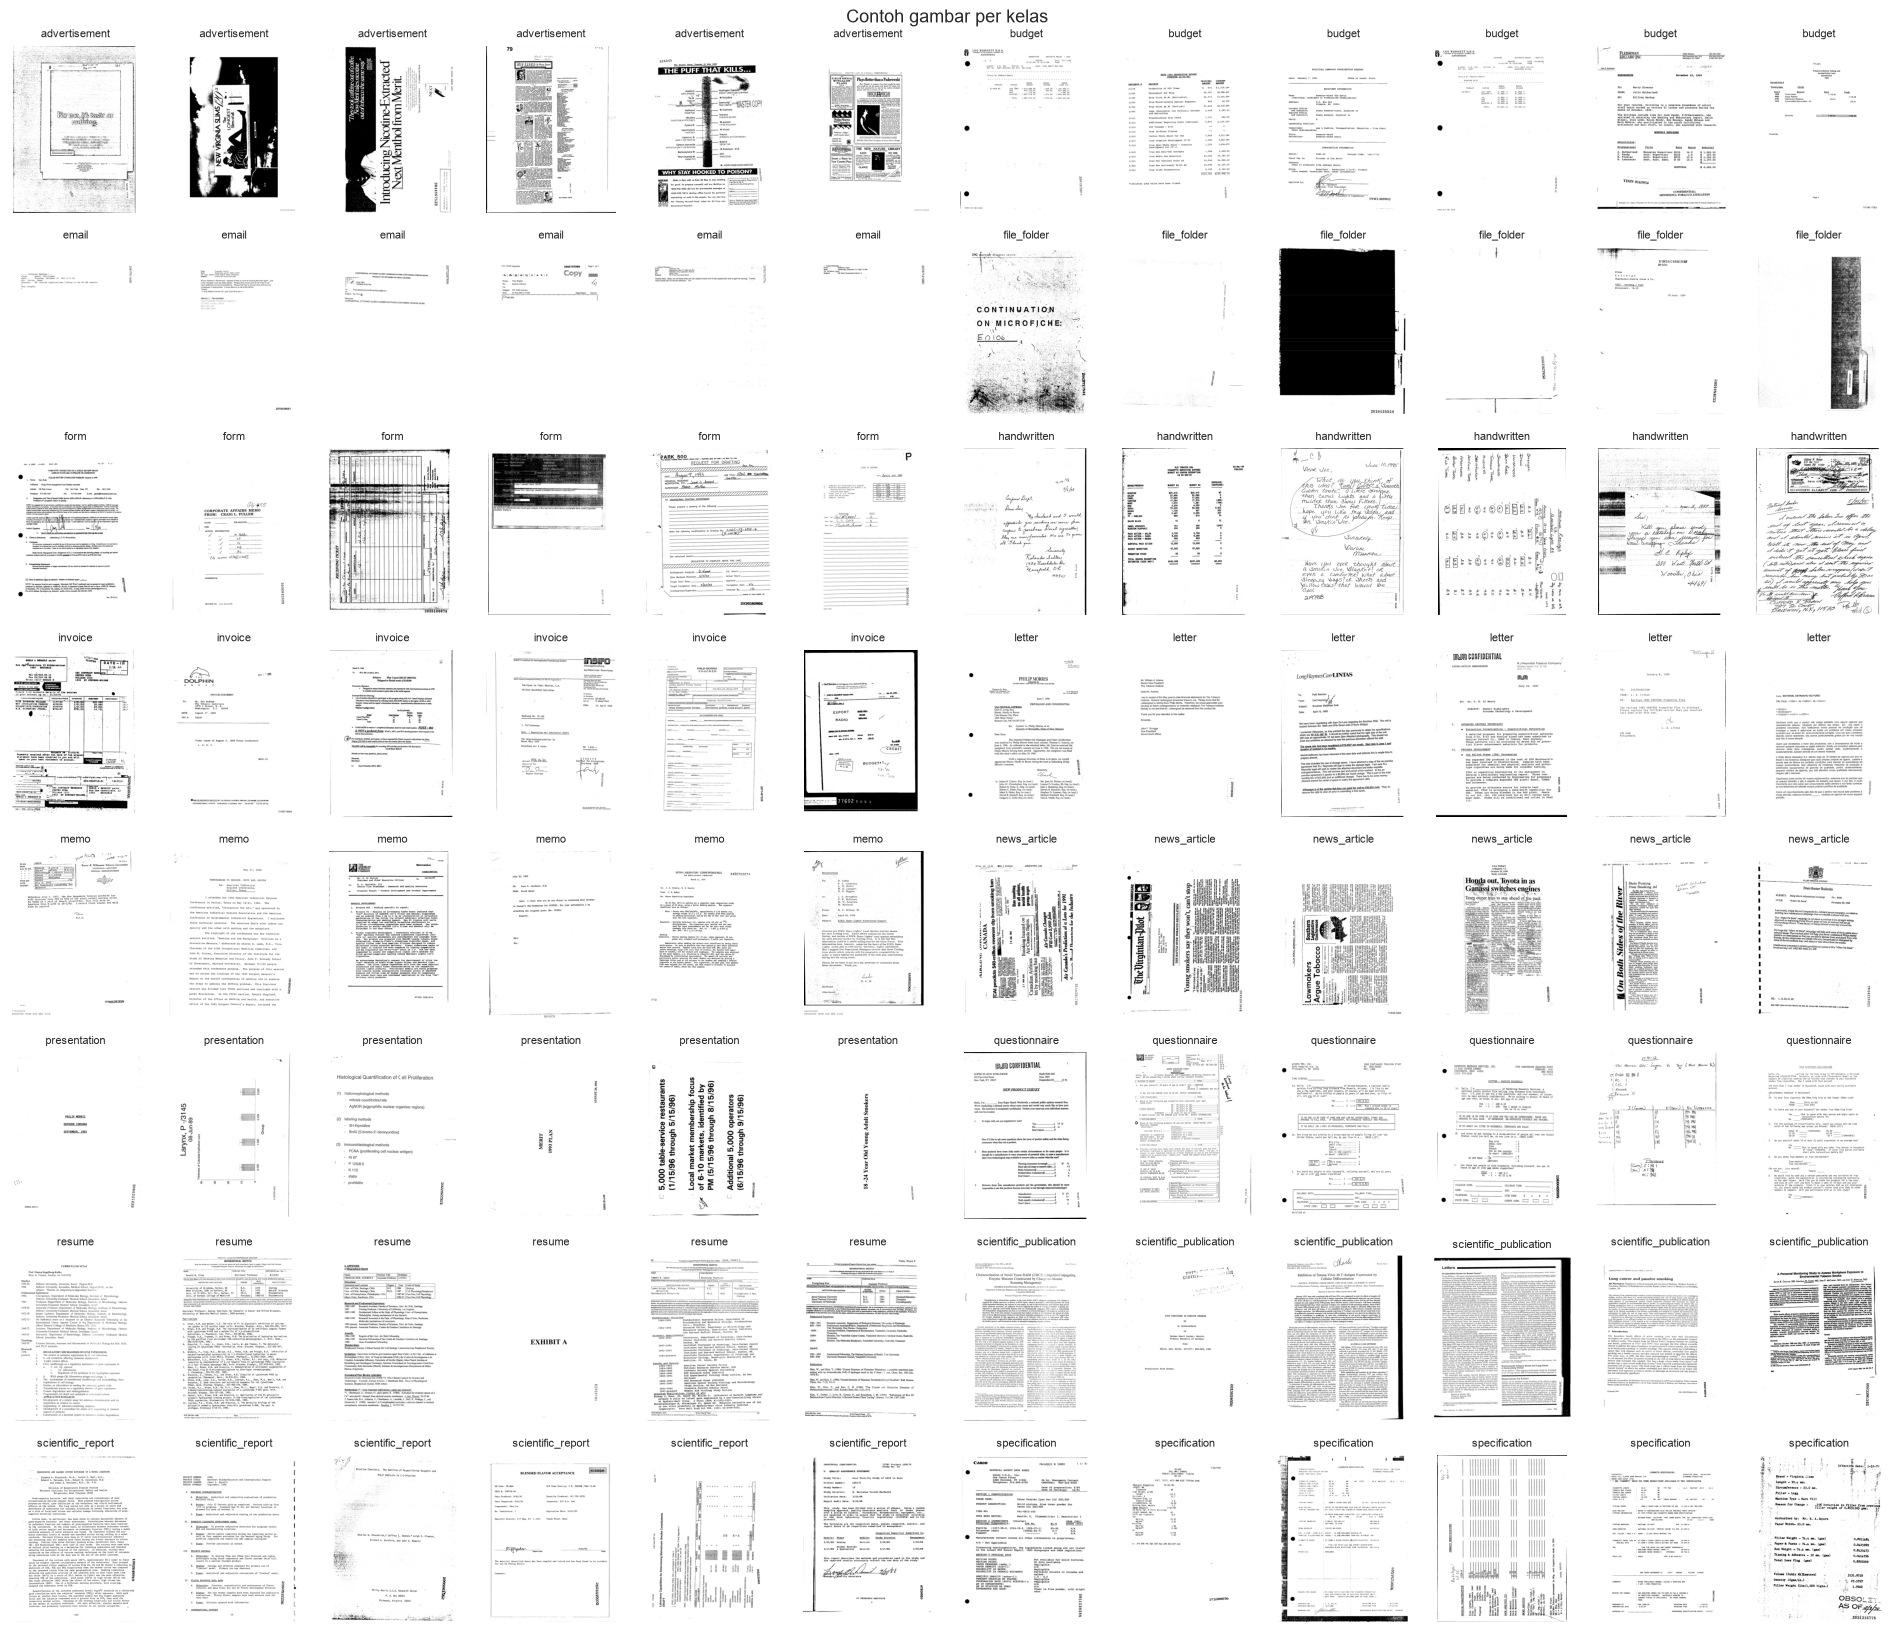

In [29]:
N_PER = 6
paths, titles = [], []
for c in CLASS_NAMES:
    sub = train_df[(train_df["class_name"] == c) & train_df["readable"]]
    pick = sub.sample(min(N_PER, len(sub)), random_state=SEED)
    paths += list(pick["path"])
    titles += [c] * len(pick)
show_images(paths, titles, ncols=N_PER * 2, size=1.6, suptitle="Contoh gambar per kelas", fname="samples_per_class")

### 9.2 Kasus ekstrem

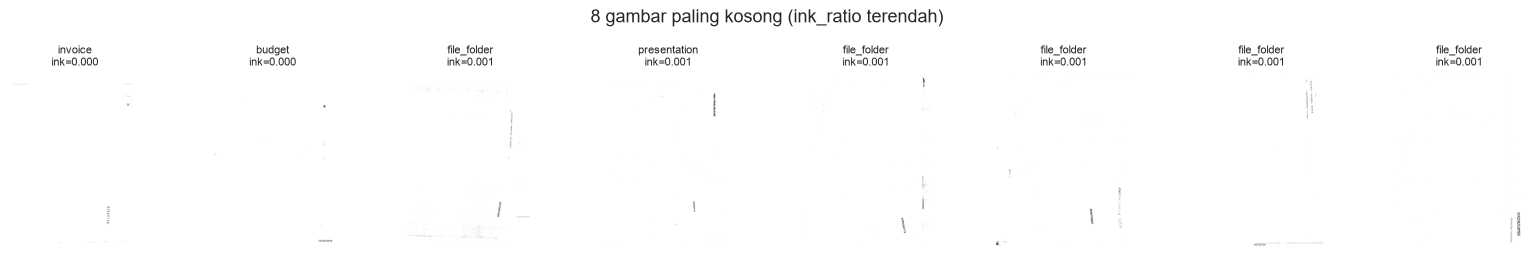

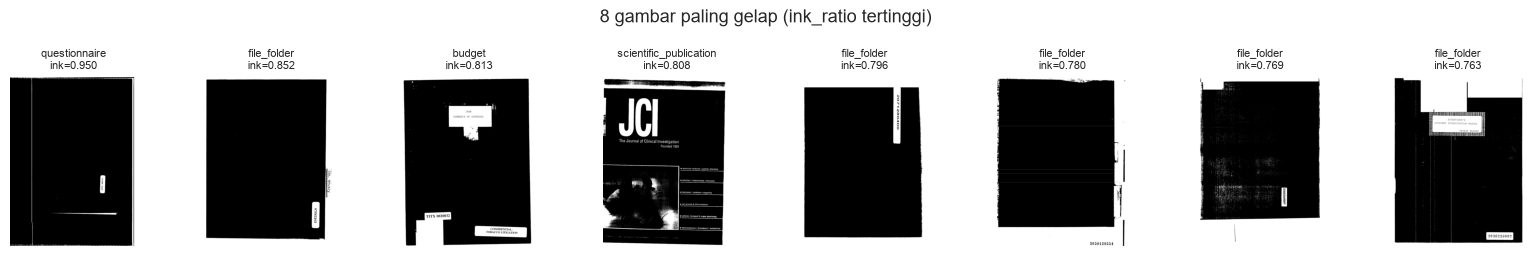

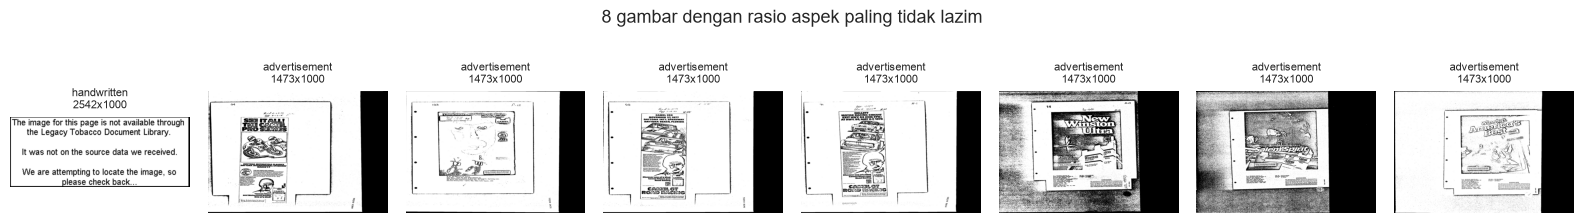

Gambar hampir kosong (ink_ratio < 0.5%) di sampel: 93 (2.91%)


class_name,file_folder,email,presentation,budget,invoice,scientific_report,letter,memo,news_article,resume,scientific_publication
n_hampir_kosong,45,28,6,4,3,2,1,1,1,1,1


In [30]:
blank = train_s.nsmallest(8, "ink_ratio")
show_images(list(blank["path"]), [f"{c}\nink={v:.3f}" for c, v in zip(blank["class_name"], blank["ink_ratio"])],
            ncols=8, suptitle="8 gambar paling kosong (ink_ratio terendah)", fname="extreme_blank")
dark = train_s.nlargest(8, "ink_ratio")
show_images(list(dark["path"]), [f"{c}\nink={v:.3f}" for c, v in zip(dark["class_name"], dark["ink_ratio"])],
            ncols=8, suptitle="8 gambar paling gelap (ink_ratio tertinggi)", fname="extreme_dark")
odd = train_df[train_df["readable"]].assign(dev=lambda d: (d["aspect_ratio"] - d["aspect_ratio"].median()).abs()).nlargest(8, "dev")
show_images(list(odd["path"]), [f"{c}\n{int(w)}x{int(h)}" for c, w, h in zip(odd["class_name"], odd["width"], odd["height"])],
            ncols=8, suptitle="8 gambar dengan rasio aspek paling tidak lazim", fname="extreme_aspect")

n_near_blank = int((train_s["ink_ratio"] < 0.005).sum())
print(f"Gambar hampir kosong (ink_ratio < 0.5%) di sampel: {n_near_blank} ({n_near_blank / len(train_s) * 100:.2f}%)")
if n_near_blank:
    display(train_s[train_s["ink_ratio"] < 0.005]["class_name"].value_counts().to_frame("n_hampir_kosong").T)

### 9.3 Perbandingan resolusi

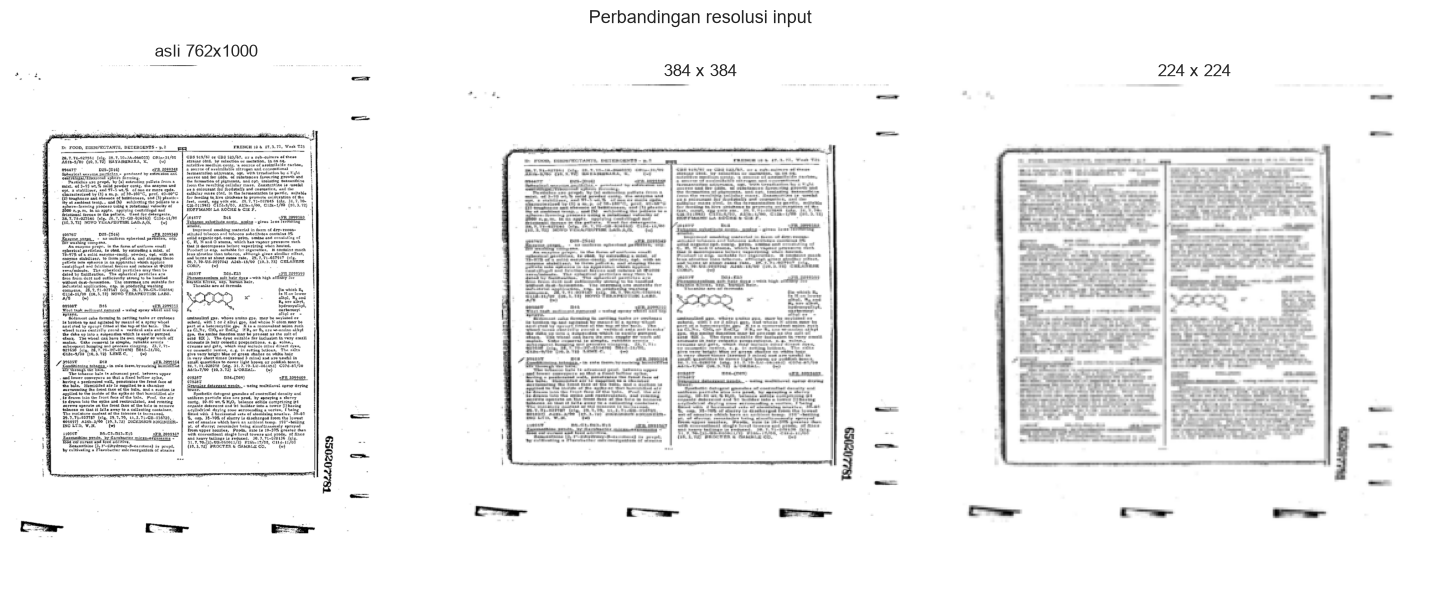

In [31]:
ex_path = train_df[(train_df["class_name"] == "scientific_publication") & train_df["readable"]].iloc[0]["path"]
with Image.open(ex_path) as im:
    im = im.convert("L")
    views = [("asli " + f"{im.width}x{im.height}", im),
             ("384 x 384", im.resize((384, 384), Image.BILINEAR)),
             ("224 x 224", im.resize((224, 224), Image.BILINEAR))]
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, (t, v) in zip(axes, views):
    ax.imshow(v, cmap="gray")
    ax.set_title(t)
    ax.axis("off")
plt.suptitle("Perbandingan resolusi input", fontsize=13)
plt.tight_layout()
save_fig("resolution_comparison")
plt.show()

## 10. Train vs Test
Kesamaan distribusi diuji dengan Kolmogorov-Smirnov dua sampel.

,fitur,median_train,median_test,KS_D,p_value
0,width,762.0000,754.0000,0.0124,0.2754
1,height,1000.0000,1000.0000,0.0000,1.0000
2,aspect_ratio,1.3123,1.3263,0.0124,0.2754
3,megapixel,0.7620,0.7540,0.0124,0.2754
4,file_kb,99.9238,98.8203,0.0137,0.1801
5,mean_intensity,0.9500,0.9509,0.0203,0.9048
6,std_intensity,0.1860,0.1827,0.0253,0.7029
7,ink_ratio,0.0486,0.0465,0.0226,0.8236
8,edge_density,0.0292,0.0280,0.0323,0.3975
9,blank_row_ratio,0.2220,0.2290,0.0304,0.4707


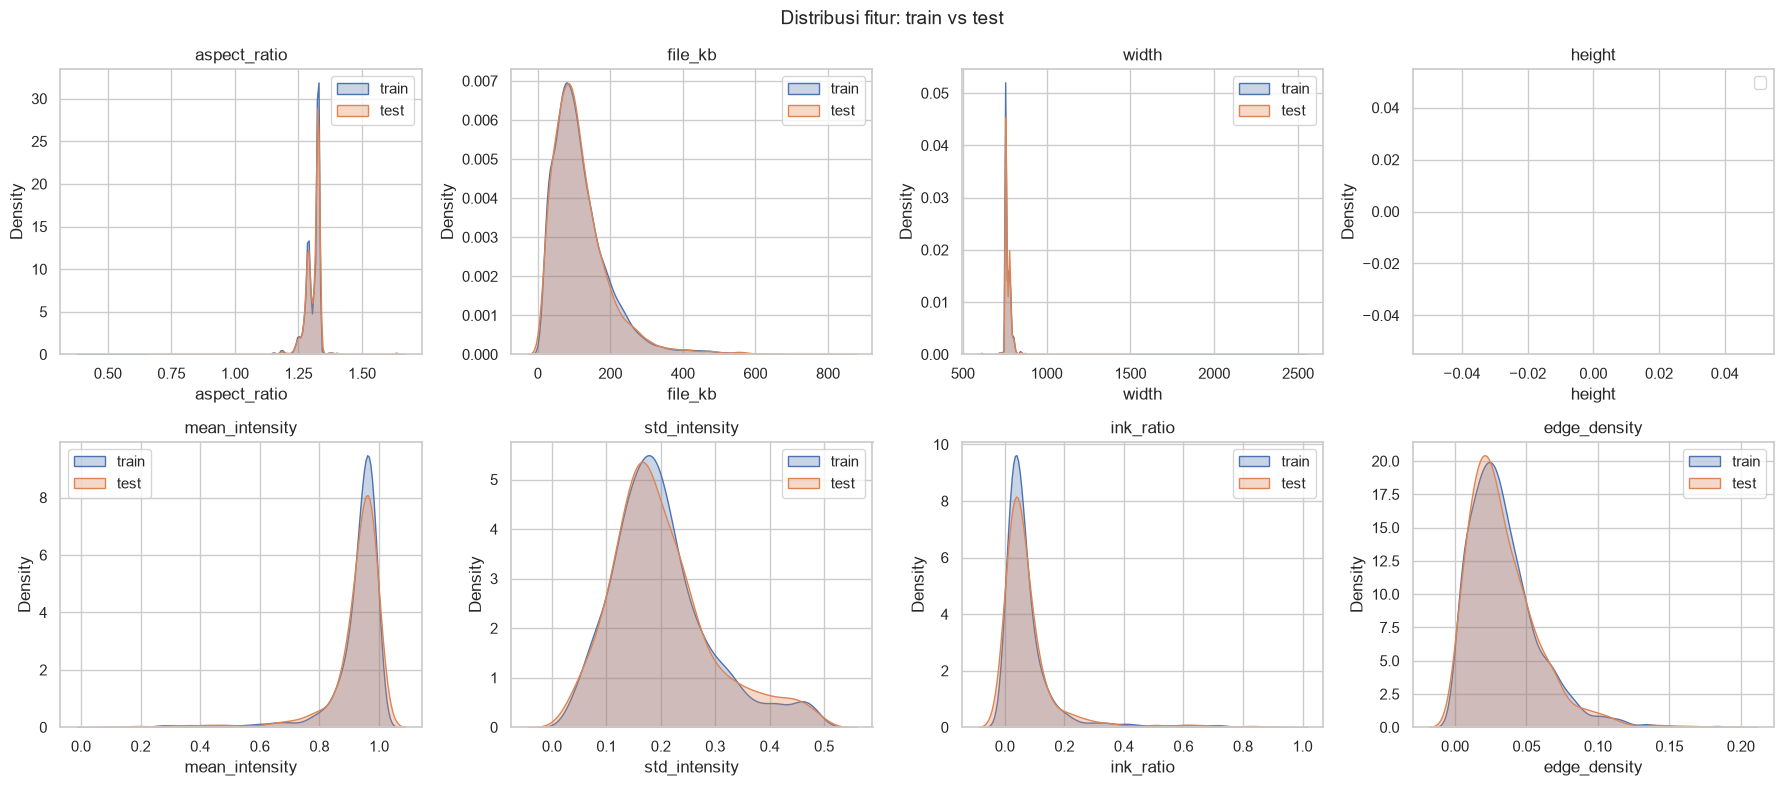

In [32]:
rows = []
for c in NUM_FEATS:
    a = (train_df if c in HEADER_FEATS else train_s)[c].dropna()
    b = (test_df if c in HEADER_FEATS else test_s)[c].dropna()
    d, p = stats.ks_2samp(a, b)
    rows.append({"fitur": c, "median_train": a.median(), "median_test": b.median(), "KS_D": d, "p_value": p})
ks = pd.DataFrame(rows)
display(ks)
ks.to_csv(METRIC_DIR / "eda_train_test_ks.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), ["aspect_ratio", "file_kb", "width", "height"] + PIXEL_FEATS[:4]):
    a = (train_df if c in HEADER_FEATS else train_s)[c]
    b = (test_df if c in HEADER_FEATS else test_s)[c]
    sns.kdeplot(a, ax=ax, label="train", fill=True, alpha=0.3, warn_singular=False)
    sns.kdeplot(b, ax=ax, label="test", fill=True, alpha=0.3, warn_singular=False)
    ax.set_title(c)
    ax.legend()
plt.suptitle("Distribusi fitur: train vs test", fontsize=14)
plt.tight_layout()
save_fig("train_vs_test")
plt.show()

## 11. Ringkasan

In [33]:
summary = {
    "jumlah_train": len(train_df),
    "jumlah_test": len(test_df),
    "jumlah_kelas": train_df["class_name"].nunique(),
    "min_per_kelas": int(label_counts.min()),
    "max_per_kelas": int(label_counts.max()),
    "rasio_imbalance": round(float(imbalance), 4),
    "file_train_rusak": int((~train_df["readable"]).sum()),
    "file_test_rusak": int((~test_df["readable"]).sum()),
    "mode_warna_dominan": train_df["mode"].mode().iat[0],
    "pct_portrait_train": round(float((train_df["orientation"] == "portrait").mean() * 100), 2),
    "median_lebar": float(train_df["width"].median()),
    "median_tinggi": float(train_df["height"].median()),
    "median_aspect_ratio": round(float(train_df["aspect_ratio"].median()), 4),
    "fitur_pembeda_terkuat": kw.iloc[0]["fitur"],
    "pct_hampir_kosong_sampel": round(n_near_blank / len(train_s) * 100, 2),
    "varians_pca_2_komponen_pct": round(float(cum[1] * 100), 2),
    "maks_KS_D_train_test": round(float(ks["KS_D"].max()), 4),
}
if CHECK_DUPLICATES:
    summary.update({
        "grup_duplikat_train": len(grp),
        "grup_duplikat_label_bertentangan": len(conflict),
        "test_identik_dengan_train": len(leak),
    })
summary_df = pd.Series(summary, name="nilai").to_frame()
display(summary_df)
summary_df.to_csv(METRIC_DIR / "eda_summary.csv")

,nilai
jumlah_train,32003
jumlah_test,7994
jumlah_kelas,16
min_per_kelas,1948
max_per_kelas,2056
rasio_imbalance,1.0554
file_train_rusak,1
file_test_rusak,0
mode_warna_dominan,L
pct_portrait_train,99.9100


## 12. Kesimpulan

**Struktur dan kualitas data**
- Data train terdiri dari 32.003 gambar dalam 16 kelas dan data test 7.994 gambar. Tidak ditemukan missing value pada ketiga file CSV.
- Kolom `filename` pada `train.csv` sesuai dengan file pada folder, dan label pada CSV sama dengan nama folder.
- Terdapat 1 file train (kelas scientific_publication) yang tidak dapat dibuka.
- Ditemukan 11 grup gambar identik di train (59 file). Tiga grup di antaranya memiliki label berbeda, berisi 21, 15, dan 7 file yang tersebar di 3 sampai 5 kelas. Gambar yang sama dengan label berbeda tidak memberi informasi yang konsisten bagi model.
- Sebanyak 25 gambar test identik dengan gambar train, dan terdapat 16 duplikat di dalam test.

**Distribusi kelas**
- Jumlah gambar per kelas berkisar 1.948 sampai 2.056 (rasio 1,06). Data dapat dianggap seimbang, sehingga accuracy layak digunakan sebagai metrik dan pembobotan kelas tidak diperlukan.

**Karakteristik gambar**
- Seluruh gambar grayscale 8-bit (mode L), 72 dpi, kompresi PackBits, dan satu frame.
- Tinggi seluruh gambar 1.000 piksel dengan lebar median 762 piksel (rasio aspek median 1,31). Sebanyak 99,9% gambar berorientasi portrait, termasuk kelas presentation, sehingga orientasi tidak dapat dijadikan pembeda kelas.
- Sebagian besar halaman didominasi latar putih (median `ink_ratio` 4,9%) dan distribusi fitur piksel menceng. Sekitar 2,9% sampel hampir kosong, paling banyak dari kelas file_folder dan email.
- Seluruh fitur berbeda signifikan antar kelas (Kruskal-Wallis, p < 0,001). Efek terbesar terdapat pada `edge_density` (ε² = 0,31), diikuti `mean_intensity`, `file_kb`, dan `ink_ratio` (ε² ≈ 0,27). Kelas advertisement paling padat tinta, sedangkan file_folder dan email paling kosong.
- `ink_ratio`, `mean_intensity`, dan `std_intensity` berkorelasi hampir sempurna (|ρ| > 0,99) sehingga pada dasarnya mengukur hal yang sama. `file_kb` berkorelasi kuat dengan `edge_density` (ρ = 0,97) karena halaman dengan banyak detail menghasilkan file yang lebih besar setelah kompresi.
- Citra rata-rata menunjukkan pola tata letak yang khas, antara lain blok header di bagian atas pada email, pola dua kolom pada scientific_publication, bingkai tepi pada handwritten, serta advertisement dan file_folder yang gelap merata.
- Dua komponen utama PCA hanya menjelaskan 46% variasi piksel. Pada t-SNE, hanya email, file_folder, specification, serta sebagian advertisement dan budget yang membentuk kelompok, sedangkan kelas lain saling tumpang tindih. Fitur piksel sederhana tidak cukup untuk membedakan kelas, sehingga diperlukan model yang mampu mempelajari pola tata letak dan teks seperti CNN.

**Train vs test**
- Statistik KS maksimum 0,032 dan seluruh p-value > 0,05. Distribusi train dan test serupa, sehingga akurasi validasi diharapkan mewakili akurasi pada data test.

**Keputusan preprocessing**
1. File yang rusak dan grup duplikat berlabel bertentangan dikeluarkan dari data latih. Duplikat lainnya disisakan satu file per grup agar gambar yang sama tidak muncul di train dan validation sekaligus.
2. Gambar dikonversi menjadi 3 kanal agar sesuai dengan bobot pre-trained ImageNet.
3. Gambar di-resize ke ukuran persegi (224 untuk baseline, 384 untuk model akhir). Rasio aspek hampir seragam di semua kelas, sehingga distorsi akibat resize tidak menimbulkan bias antar kelas.
4. Augmentasi yang digunakan bersifat ringan: rotasi kecil, translasi, serta perubahan kecerahan dan kontras. Flip dan rotasi 90° tidak digunakan karena tidak sesuai dengan kondisi dokumen asli.
5. Data train dibagi menjadi train dan validation secara stratified.